In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
import os
import random
import numpy as np
import torch
def seed_everything(seed=42):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    torch.use_deterministic_algorithms(True,warn_only=True)


seed_everything(42)

In [3]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from torch.utils.data import DataLoader
from torchvision import transforms
from matplotlib import pyplot as plt
import torch.optim as optim
import seaborn as sns
import torch.nn as nn
import numpy as np
import cv2 as cv
import random
import torch
import os

from domain.mvcnn_dataset import MVCNNDataset
from domain.mvcnn_model import MVCNNModel
from domain.history_model import HistoryModel
from domain.mvcnn_grad_cam import MVCNNGradCAM
from domain.cros_validation_history import CrossValidationHistory

Varaiveis globais utilizadas nas funções

In [4]:
cros_validation_history:dict[float, CrossValidationHistory] = {}
num_classes = 4

In [5]:
def listar_diretorio(path):
    return [os.path.join(path, path_image) for path_image in os.listdir(path)]

In [6]:
classes_shrimp = ["P. brasiliensis", "P. isabelae", "P. paulensis", "P. subtilis"]

class_to_idx = [
    i for i in range(0, len(classes_shrimp))
]
print(class_to_idx)

class_to_idx = {
    cls: i for i, cls in enumerate(classes_shrimp)
}

[0, 1, 2, 3]


In [7]:
from pathlib import Path

views_list_image_paths = []
labels_paths = []
for path in Path("../dataset_segmentation_cinza/").iterdir():

    if path.is_dir():
        label = path.name
        
        for class_dir in path.iterdir():

            if class_dir.iterdir():
                views_list_image_paths.append(listar_diretorio(class_dir))
                labels_paths.append(label)

print(len(views_list_image_paths))
print(len(labels_paths))

199
199


In [8]:
train_transform = transforms.Compose([ # Aplicando data argumentation na base de treino e aplicando transformadores para padronizar as imagens
    transforms.Resize((256,256)), # reduzindo tamanho das imagens

    transforms.RandomResizedCrop(
        224,
        scale=(0.8,1.0)
    ),

    transforms.RandomHorizontalFlip(p=0.5), # rotacionando imagens

    transforms.RandomRotation(15),# rotacionaod imagens

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize( # Normalizando dados
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [9]:
val_test_transform = transforms.Compose([
    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

Função para validação do modelo

In [10]:
def validate_model(model, val_loader, criterion, fold_id, history):

    device = next(model.parameters()).device

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            probs = torch.softmax(outputs, dim=1).cpu().numpy()

            all_probs.extend(probs)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

            history.add_all_label_fold(labels.cpu().numpy(), fold_id)
            history.add_all_prob_fold(probs, fold_id)
            history.add_all_pred_fold(preds.cpu().numpy(), fold_id)
            
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total
    history.add_val_loss_fold(epoch_loss, fold_id)
    history.add_val_acc_fold(epoch_acc, fold_id)

    f1_macro = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    return epoch_loss, epoch_acc, f1_macro

Função para treinamento do modelo

In [11]:
def train_model(model, train_loader, criterion, optimizer, history, num_epochs, fold_id):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    
    print(device)
    model = model.to(device)
    
    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (preds == labels).sum().item()

        epoch_loss = running_loss / total
        epoch_acc = 100 * correct / total

        history.add_train_loss_fold(epoch_loss, fold_id)
        history.add_train_acc_fold(epoch_acc, fold_id)

Função para teste do modelo

In [12]:
def test_model(model, test_loader, criterion, fold_id):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []
    running_loss = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            probs = torch.softmax(outputs, dim=1).cpu().numpy()

            all_probs.extend(probs)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

            cros_validation_history.add_all_label_fold(labels.cpu().numpy(), fold_id)
            cros_validation_history.add_all_prob_fold(probs, fold_id)
            cros_validation_history.add_all_pred_fold(preds.cpu().numpy(), fold_id)

    test_loss = running_loss / len(test_loader.dataset)
    test_acc = 100 * accuracy_score(all_labels, all_preds)

    f1_macro = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )


    # evaluate_model(
    #     dataset=test_loader.dataset,
    #     all_labels=all_labels,
    #     all_preds=all_preds,
    #     all_probs=all_probs
    # )

    return test_loss, test_acc, f1_macro

Função para avaliação do modelo

In [13]:
def evaluate_model(classes_names, all_labels, all_preds, all_probs):
    class_names = classes_names

    print(f"\nAcurácia final: {accuracy_score(all_labels, all_preds)*100:.2f}%")
    print(f"F1-score macro: {f1_score(all_labels, all_preds, average='macro'):.2f}")
    print(f"F1-score weighted: {f1_score(all_labels, all_preds, average='weighted'):.2f}")

    print("\nClassification Report")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe verdadeira")
    plt.title("Matriz de Confusão no Conjunto de Teste")
    plt.tight_layout()
    plt.show()

    # One-hot encoding dos rótulos verdadeiros
    y_true = label_binarize(all_labels, classes=list(range(4)))
    y_score = np.array(all_probs)

    # Plotar curva ROC para cada classe
    plt.figure(figsize=(10, 8))
    for i in range(4):
        fpr, tpr, _ = roc_curve(y_true[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.title('Curvas ROC por Classe')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Função para execução dos folds em calidação cruzada

In [14]:
def run_fold(X_train, y_train, X_val, y_val, fold_id, history, batch_size=8, num_epochs=50, learning_rate=0.001, pooling=nn.AdaptiveMaxPool1d(1)):

    train_dataset = MVCNNDataset(X_train,
        y_train,
        classes_shrimp,
        train_transform
    )

    val_dataset = MVCNNDataset(
        X_val,
        y_val,
        classes_shrimp,
        val_test_transform
    )

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = MVCNNModel(
        num_classes=len(classes_shrimp),
        aggregation=pooling
    )

    history.add_model(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    train_model(
        model,
        train_loader,
        criterion,
        optimizer,
        history,
        num_epochs,
        fold_id
    )

    loss, acc, f1 = validate_model(model, val_loader, criterion, fold_id, history)

    return loss, acc, f1

Função para plotar Grad CAM

In [15]:
def plot_gradcam(model: MVCNNModel,dataset: MVCNNDataset,sample:int):

    cams = MVCNNGradCAM(model)

    heatmaps = cams.generate(
        dataset[sample][0]
    )

    images = dataset[sample][0]

    nomes = ["6º Somito","Carapaça","Sulco Adrostral"]

    fig,ax = plt.subplots(
        3,
        2,
        figsize=(8,6)
    )

    views, label = dataset[sample]

    for i in range(len(images)):
        original_width, original_height = dataset.list_sizes[sample][i]

        img = images[i].permute(
            1,2,0
        ).numpy()

        img -= img.min()
        img /= img.max()

        img_original = cv.resize(
            img,
            (original_width, original_height),
            interpolation=cv.INTER_LINEAR
        )

        heat = cv.resize(
            heatmaps[i],
            (original_width, original_height),
            interpolation=cv.INTER_LINEAR
        )

        heat = cv.applyColorMap(
            np.uint8(255*heat),
            cv.COLORMAP_JET
        )

        heat = cv.cvtColor(
            heat,
            cv.COLOR_BGR2RGB
        )

        overlay = cv.addWeighted(
            np.uint8(img_original*255),
            0.55,
            heat,
            0.45,
            0
        )

        ax[i,0].imshow(img_original)
        ax[i,0].set_aspect("equal")
        ax[i,0].set_title(nomes[i])
        ax[i,0].axis("off")

        ax[i,1].imshow(overlay)
        ax[i,1].set_aspect("equal")
        ax[i,1].set_title("GradCAM")
        ax[i,1].axis("off")

    plt.tight_layout()

Busca de hiperparâmeotrs ( Modificando Learning Rate)

In [16]:
from sklearn.model_selection import StratifiedKFold, train_test_split

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# Valores para variação de hiperparâmetros
learning_rates = [
    0.01,
    0.001,
    0.0005,
    0.0001
]

for lr in learning_rates:

    cros_validation_history[lr] = CrossValidationHistory()

    for fold, (train_idx, test_idx) in enumerate(
        skf.split(views_list_image_paths, labels_paths),
        start=1
    ):

        history = cros_validation_history[lr]

        print(f"\n Fold {fold} - learning rate {lr}")

        # Divide treino e teste do fold
        X_train = [views_list_image_paths[i] for i in train_idx]
        y_train = [labels_paths[i] for i in train_idx]

        X_val = [views_list_image_paths[i] for i in test_idx]
        y_val = [labels_paths[i] for i in test_idx]

        # Executa um fold completo
        loss, acc, f1 = run_fold(X_train, y_train, X_val,y_val, fold, history, learning_rate=lr)
        
        history.add_fold(loss, acc, f1)

        # results.append(result)


 Fold 1 - learning rate 0.01
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 2 - learning rate 0.01
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 3 - learning rate 0.01
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (30 outputs left out)


 Fold 4 - learning rate 0.0001
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 5 - learning rate 0.0001
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Métricas Learning rate

####################################################################################
Fold: 1 ----- Learning_rates: 0.01

Acurácia final: 70.00%
F1-score macro: 0.62
F1-score weighted: 0.66

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.65      1.00      0.79        11
    P. isabelae       1.00      0.14      0.25         7
   P. paulensis       0.67      0.83      0.74        12
    P. subtilis       0.86      0.60      0.71        10

       accuracy                           0.70        40
      macro avg       0.79      0.64      0.62        40
   weighted avg       0.77      0.70      0.66        40



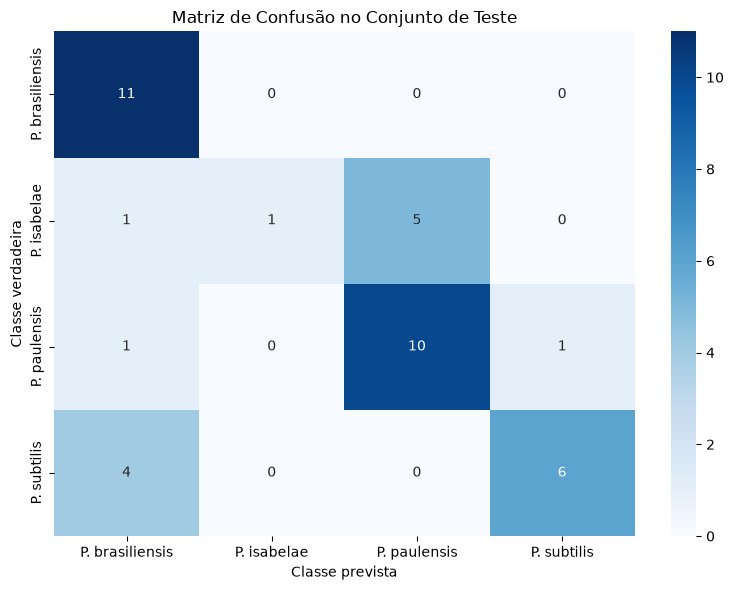

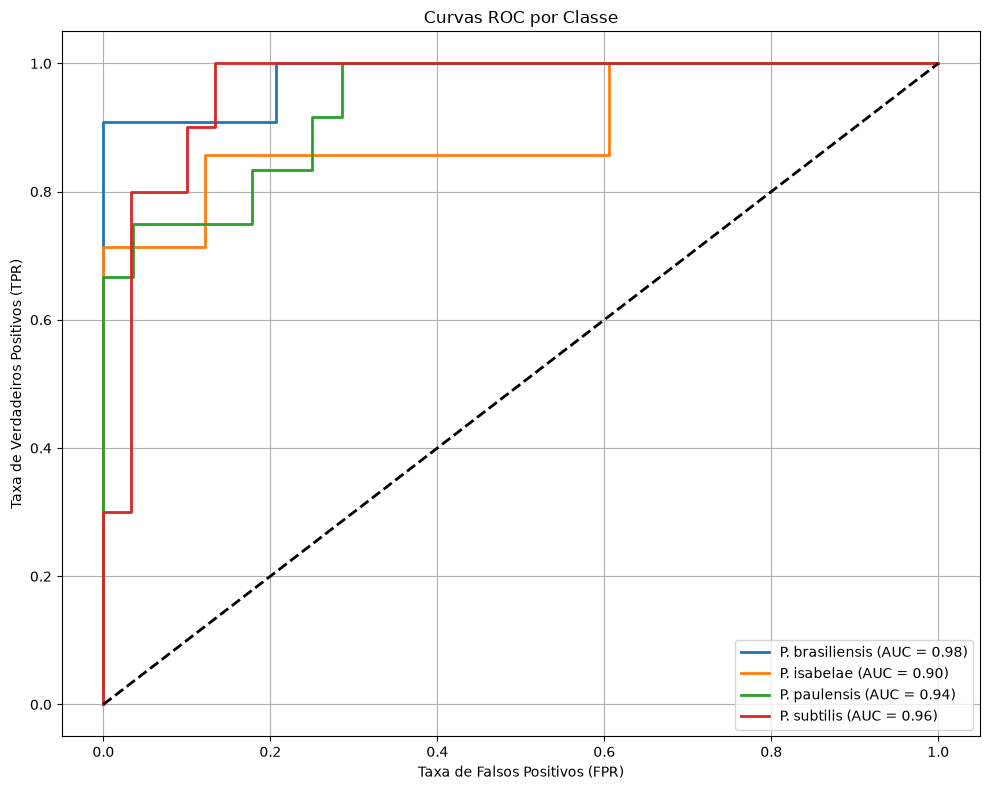

####################################################################################
Fold: 2 ----- Learning_rates: 0.01

Acurácia final: 62.50%
F1-score macro: 0.50
F1-score weighted: 0.57

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.62      0.91      0.74        11
    P. isabelae       0.00      0.00      0.00         6
   P. paulensis       0.60      0.50      0.55        12
    P. subtilis       0.64      0.82      0.72        11

       accuracy                           0.62        40
      macro avg       0.47      0.56      0.50        40
   weighted avg       0.53      0.62      0.57        40



c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

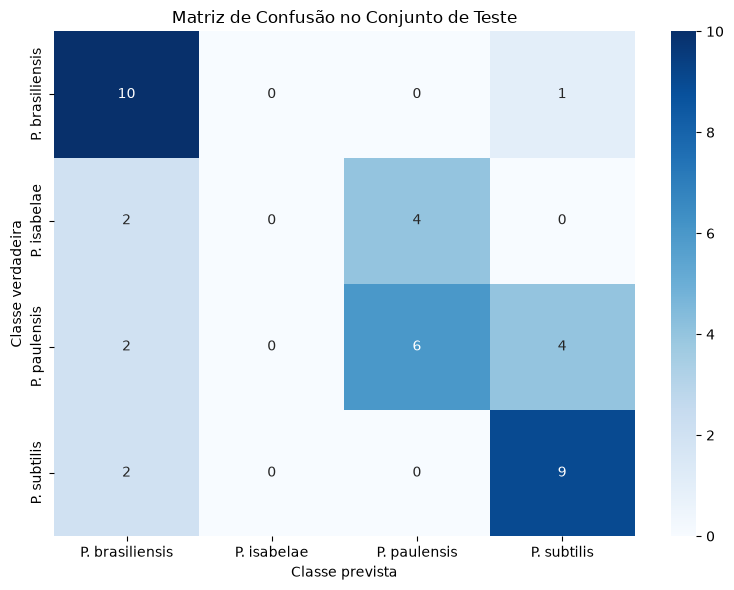

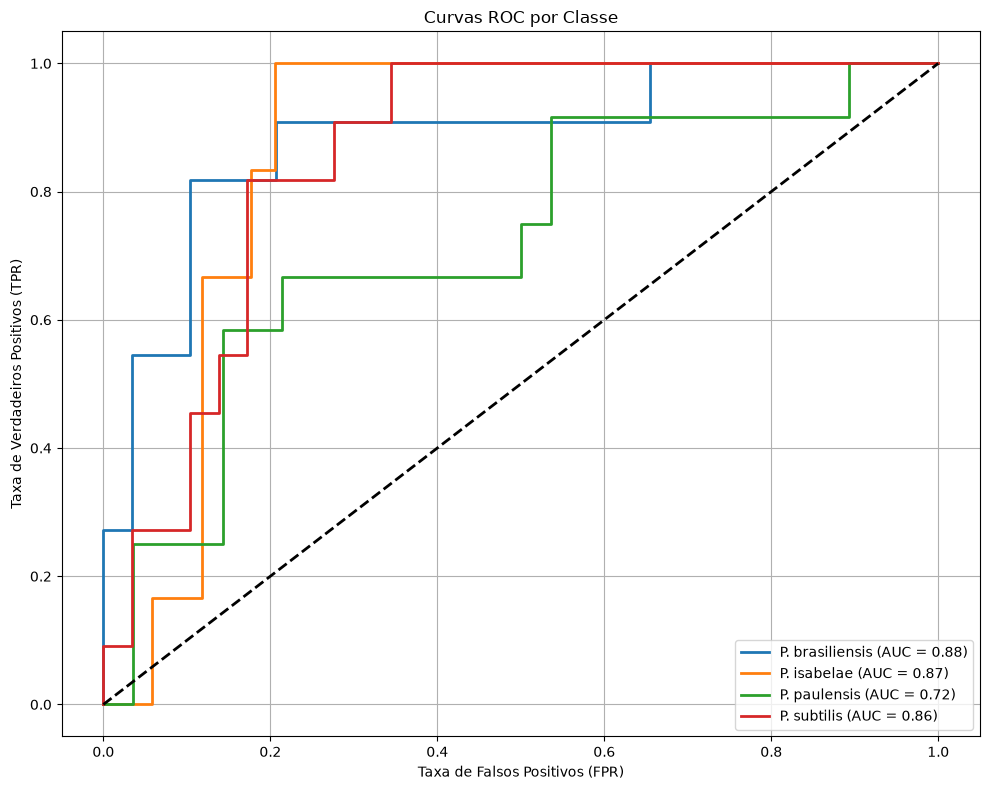

####################################################################################
Fold: 3 ----- Learning_rates: 0.01

Acurácia final: 25.00%
F1-score macro: 0.18
F1-score weighted: 0.18

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.00      0.00      0.00        10
    P. isabelae       0.19      1.00      0.32         7
   P. paulensis       1.00      0.25      0.40        12
    P. subtilis       0.00      0.00      0.00        11

       accuracy                           0.25        40
      macro avg       0.30      0.31      0.18        40
   weighted avg       0.33      0.25      0.18        40



c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

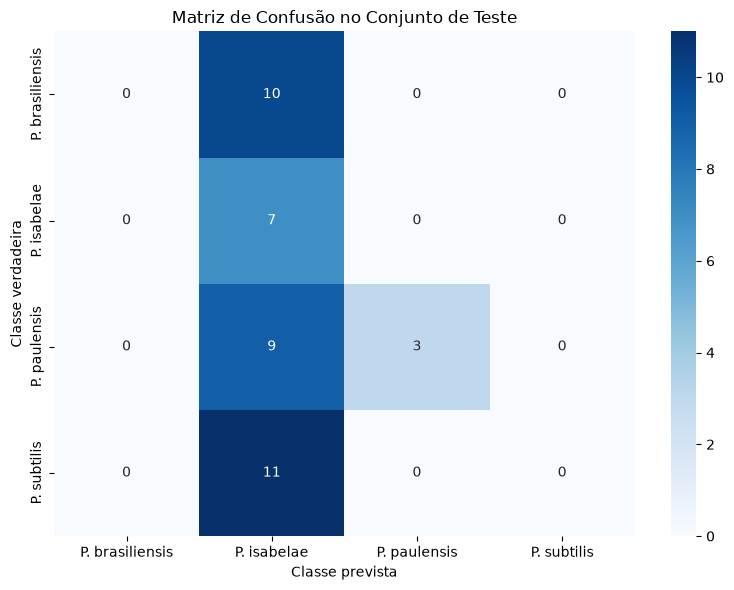

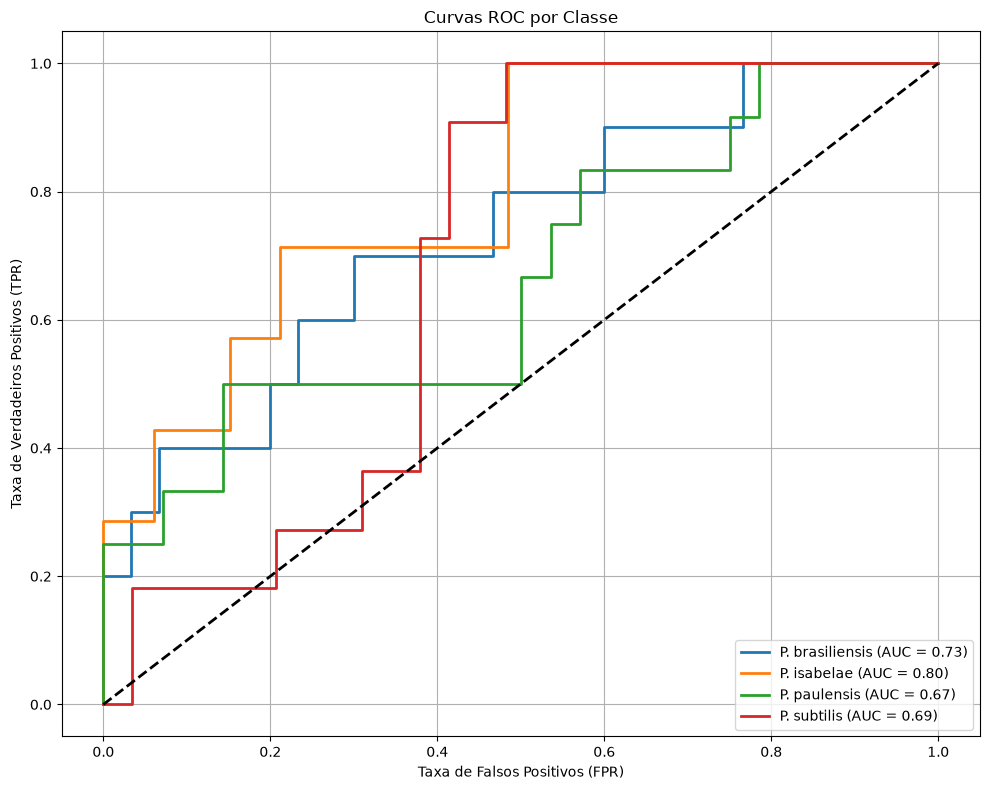

####################################################################################
Fold: 4 ----- Learning_rates: 0.01

Acurácia final: 55.00%
F1-score macro: 0.43
F1-score weighted: 0.47

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.89      0.80      0.84        10
    P. isabelae       0.00      0.00      0.00         7
   P. paulensis       0.43      1.00      0.60        12
    P. subtilis       0.67      0.18      0.29        11

       accuracy                           0.55        40
      macro avg       0.50      0.50      0.43        40
   weighted avg       0.53      0.55      0.47        40



c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

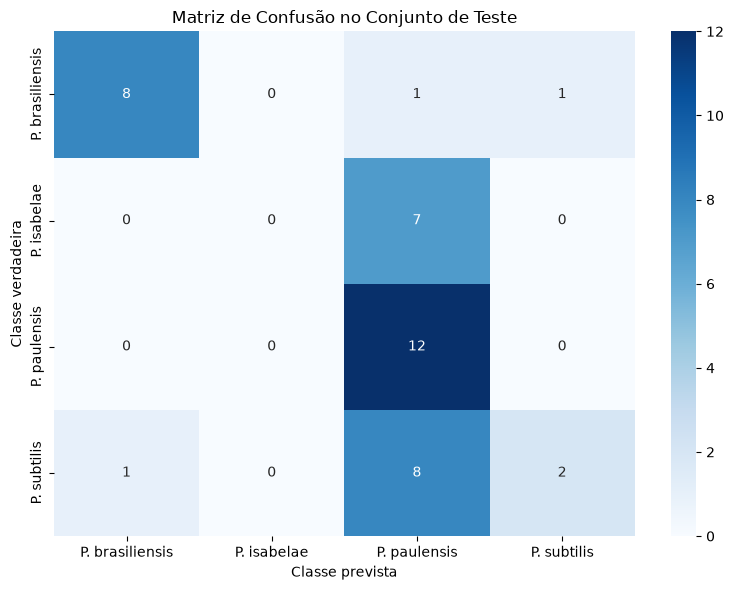

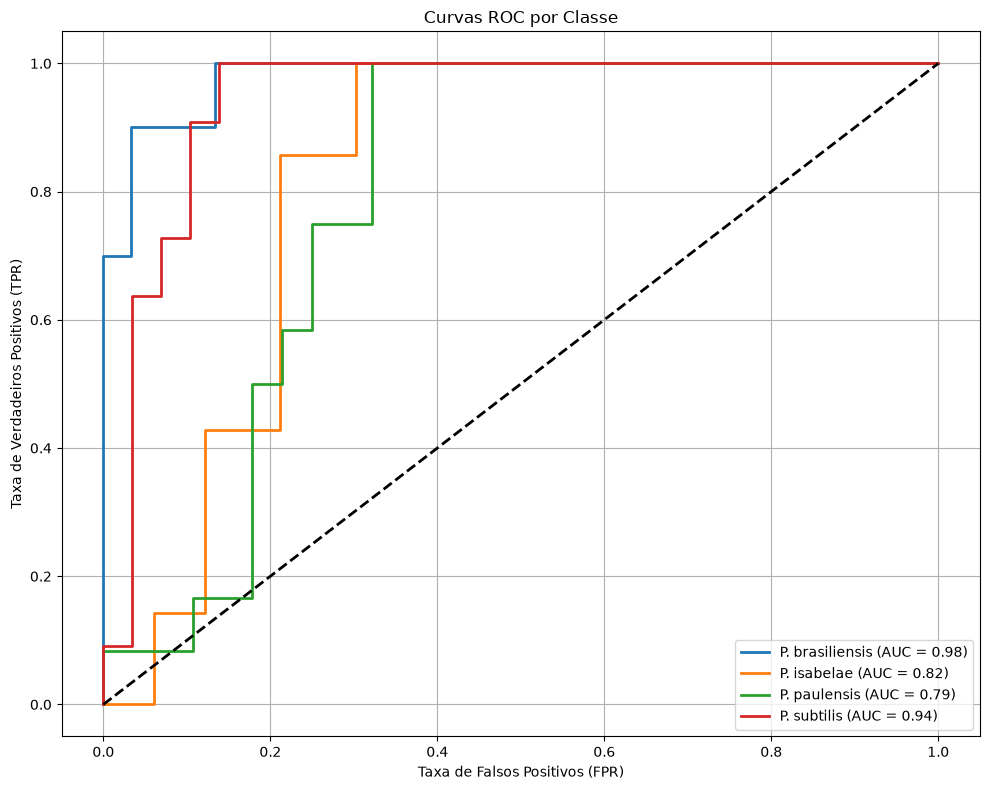

####################################################################################
Fold: 1 ----- Learning_rates: 0.001

Acurácia final: 90.00%
F1-score macro: 0.90
F1-score weighted: 0.90

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.91      0.91      0.91        11
    P. isabelae       1.00      0.86      0.92         7
   P. paulensis       0.80      1.00      0.89        12
    P. subtilis       1.00      0.80      0.89        10

       accuracy                           0.90        40
      macro avg       0.93      0.89      0.90        40
   weighted avg       0.92      0.90      0.90        40



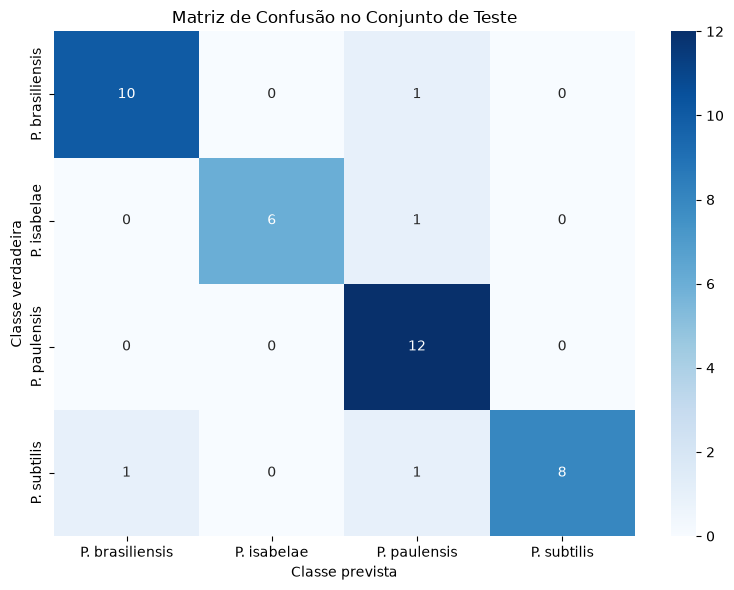

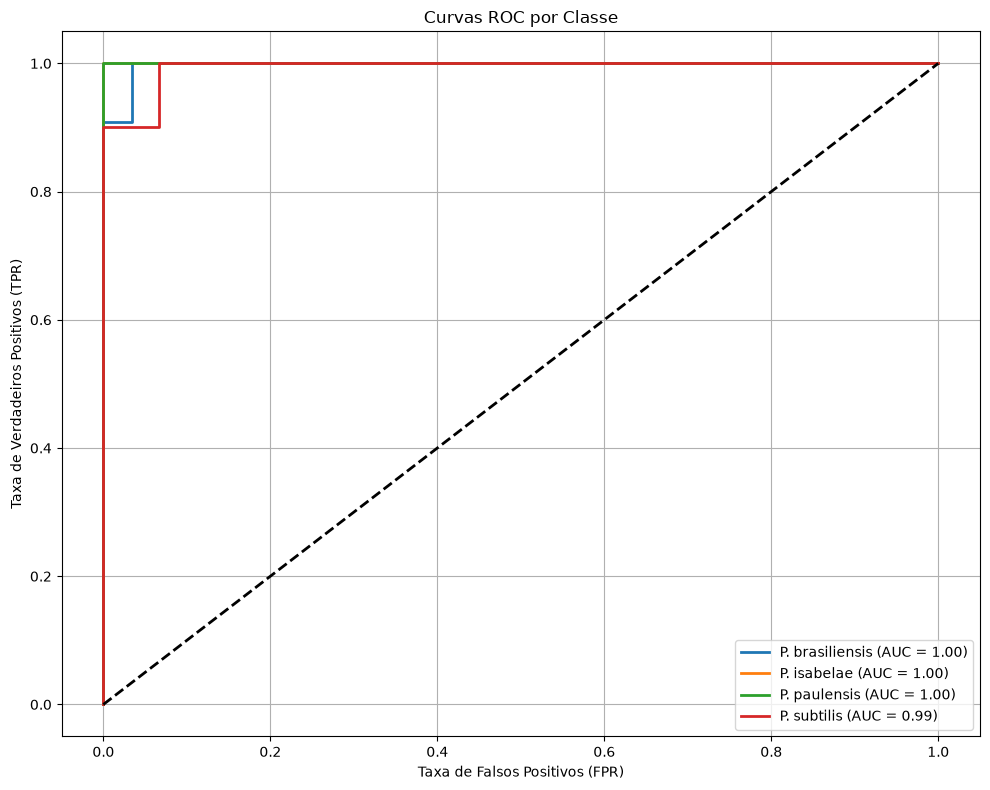

####################################################################################
Fold: 2 ----- Learning_rates: 0.001

Acurácia final: 80.00%
F1-score macro: 0.80
F1-score weighted: 0.77

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.85      1.00      0.92        11
    P. isabelae       1.00      1.00      1.00         6
   P. paulensis       1.00      0.33      0.50        12
    P. subtilis       0.65      1.00      0.79        11

       accuracy                           0.80        40
      macro avg       0.87      0.83      0.80        40
   weighted avg       0.86      0.80      0.77        40



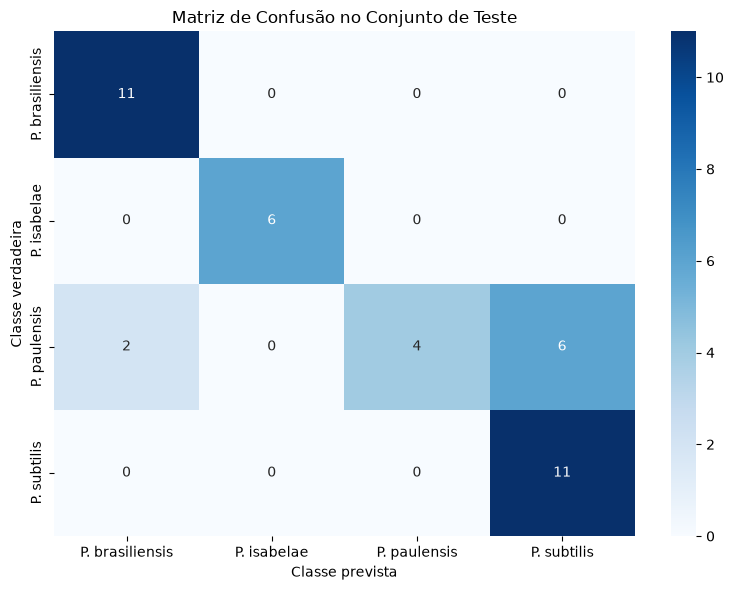

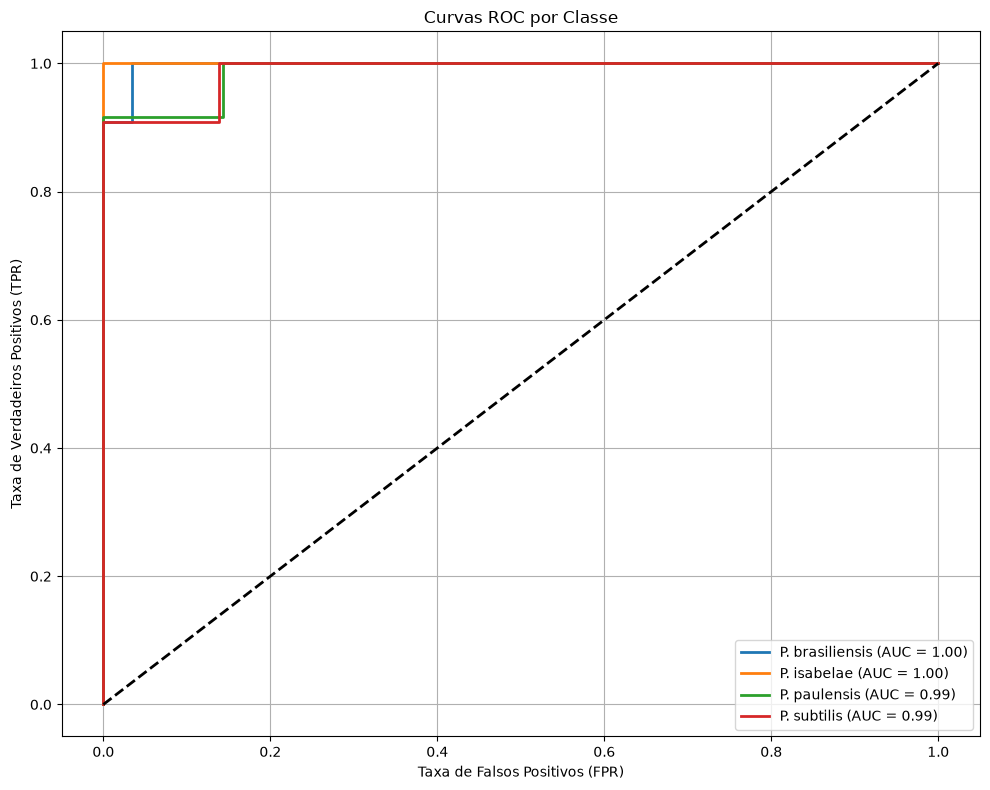

####################################################################################
Fold: 3 ----- Learning_rates: 0.001

Acurácia final: 82.50%
F1-score macro: 0.82
F1-score weighted: 0.82

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.83      1.00      0.91        10
    P. isabelae       1.00      0.71      0.83         7
   P. paulensis       1.00      0.58      0.74        12
    P. subtilis       0.69      1.00      0.81        11

       accuracy                           0.82        40
      macro avg       0.88      0.82      0.82        40
   weighted avg       0.87      0.82      0.82        40



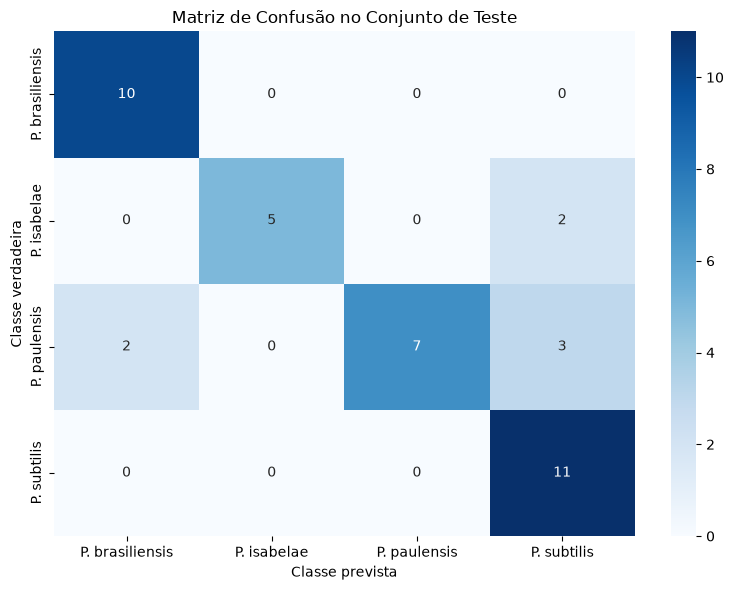

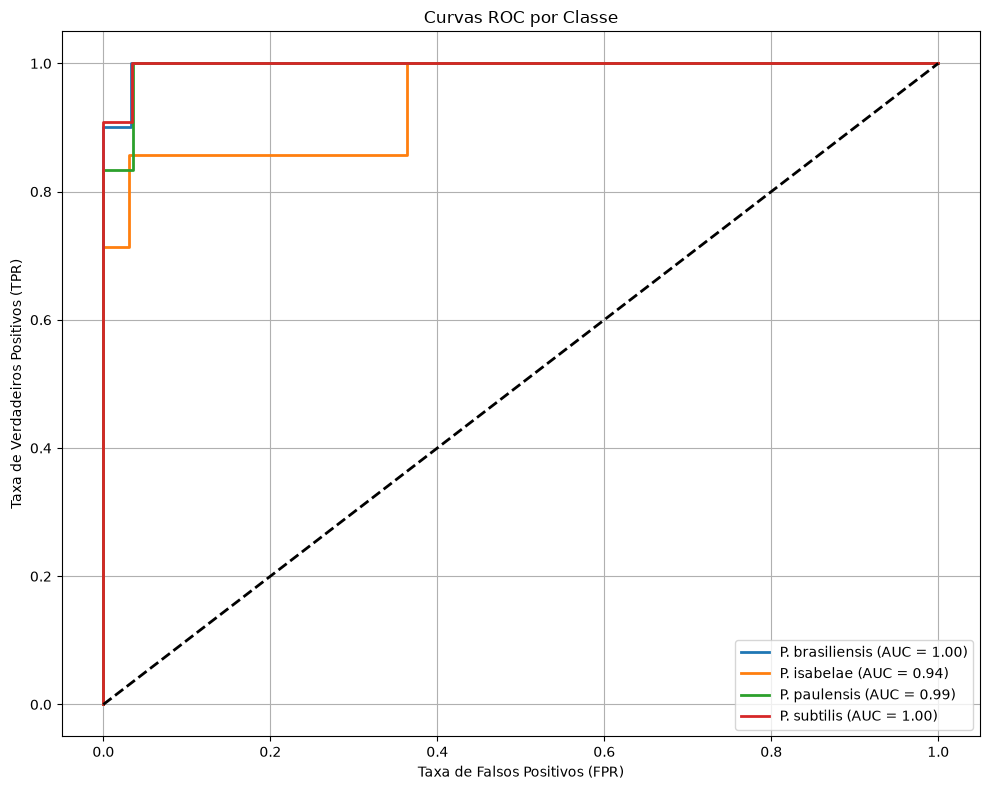

####################################################################################
Fold: 4 ----- Learning_rates: 0.001

Acurácia final: 87.50%
F1-score macro: 0.87
F1-score weighted: 0.88

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.90      0.95        10
    P. isabelae       0.58      1.00      0.74         7
   P. paulensis       1.00      0.75      0.86        12
    P. subtilis       1.00      0.91      0.95        11

       accuracy                           0.88        40
      macro avg       0.90      0.89      0.87        40
   weighted avg       0.93      0.88      0.88        40



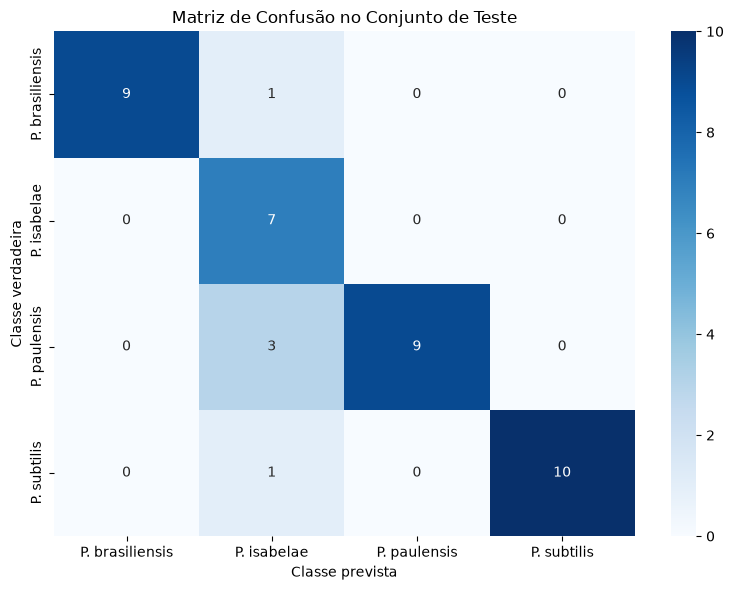

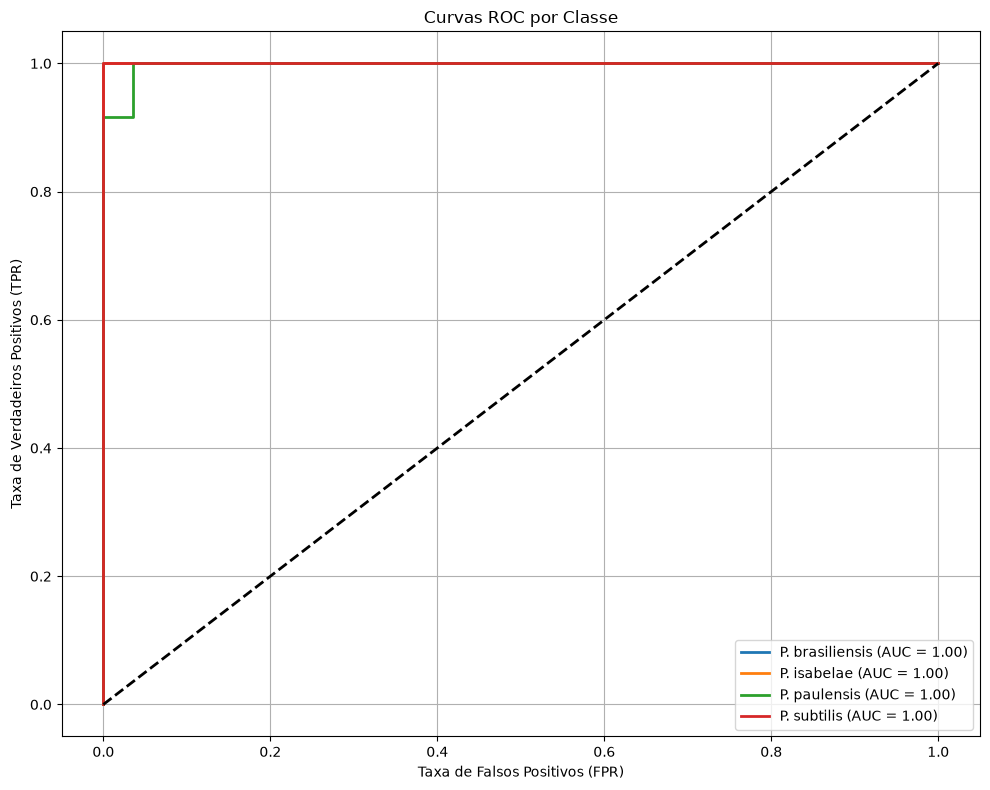

####################################################################################
Fold: 1 ----- Learning_rates: 0.0005

Acurácia final: 97.50%
F1-score macro: 0.98
F1-score weighted: 0.98

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        11
    P. isabelae       1.00      1.00      1.00         7
   P. paulensis       1.00      0.92      0.96        12
    P. subtilis       0.91      1.00      0.95        10

       accuracy                           0.97        40
      macro avg       0.98      0.98      0.98        40
   weighted avg       0.98      0.97      0.98        40



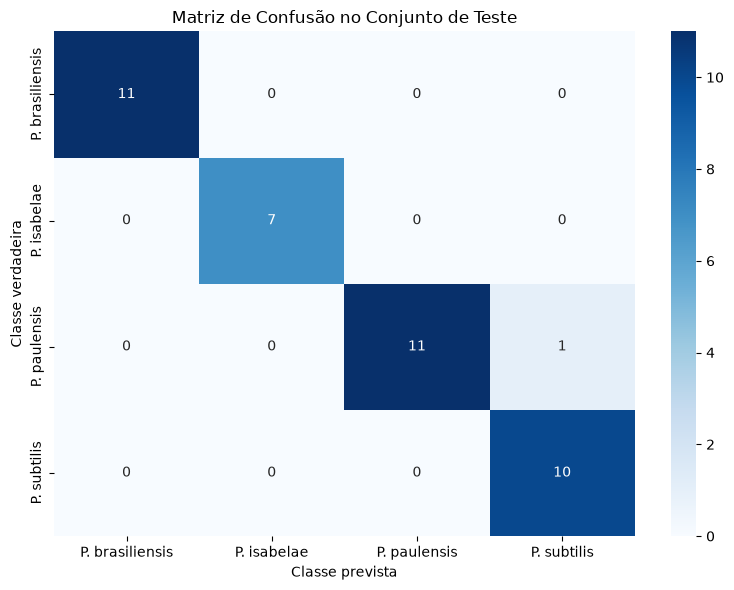

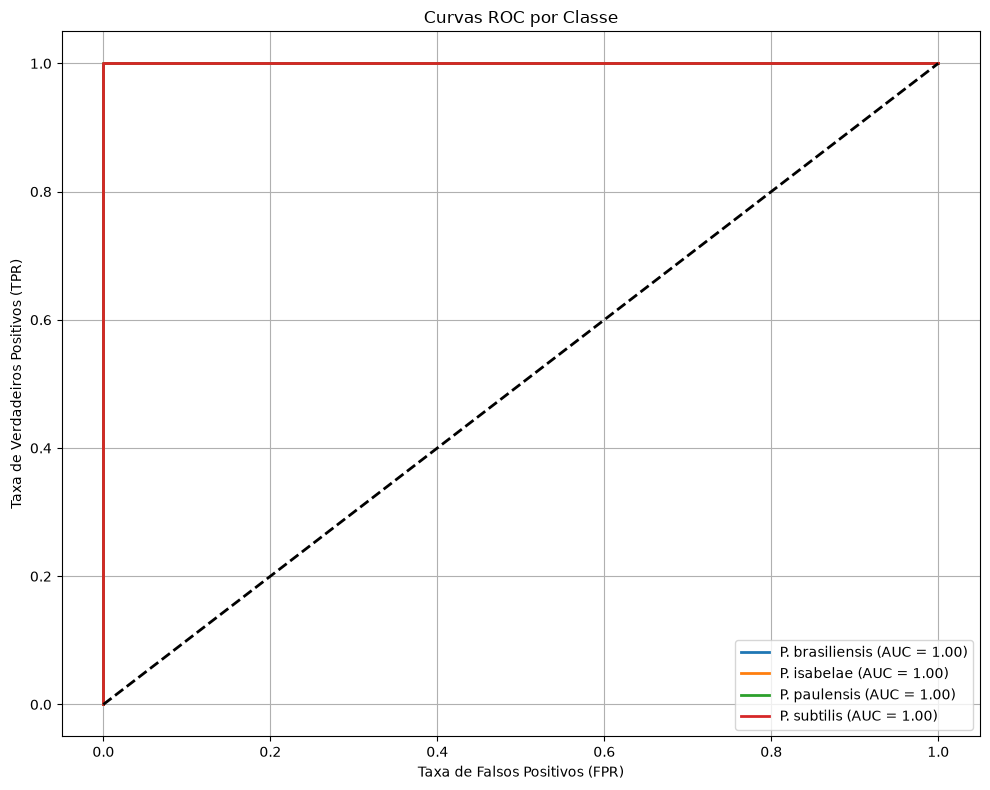

####################################################################################
Fold: 2 ----- Learning_rates: 0.0005

Acurácia final: 100.00%
F1-score macro: 1.00
F1-score weighted: 1.00

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        11
    P. isabelae       1.00      1.00      1.00         6
   P. paulensis       1.00      1.00      1.00        12
    P. subtilis       1.00      1.00      1.00        11

       accuracy                           1.00        40
      macro avg       1.00      1.00      1.00        40
   weighted avg       1.00      1.00      1.00        40



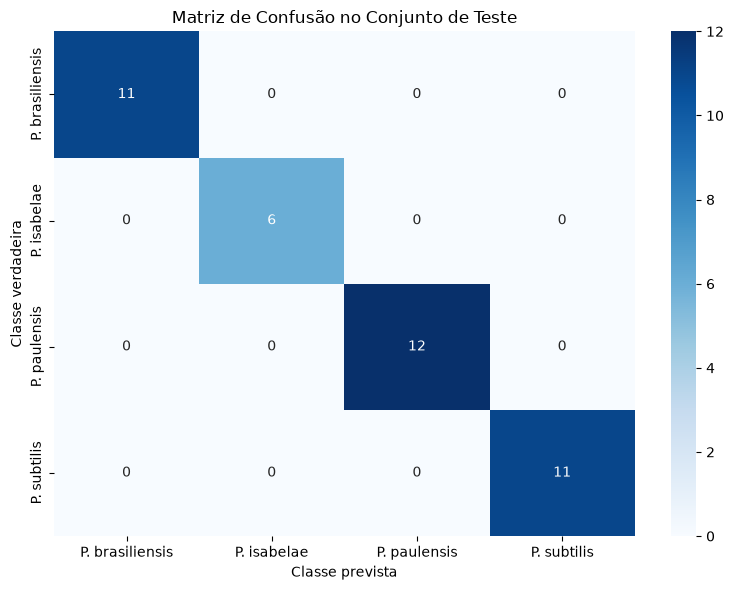

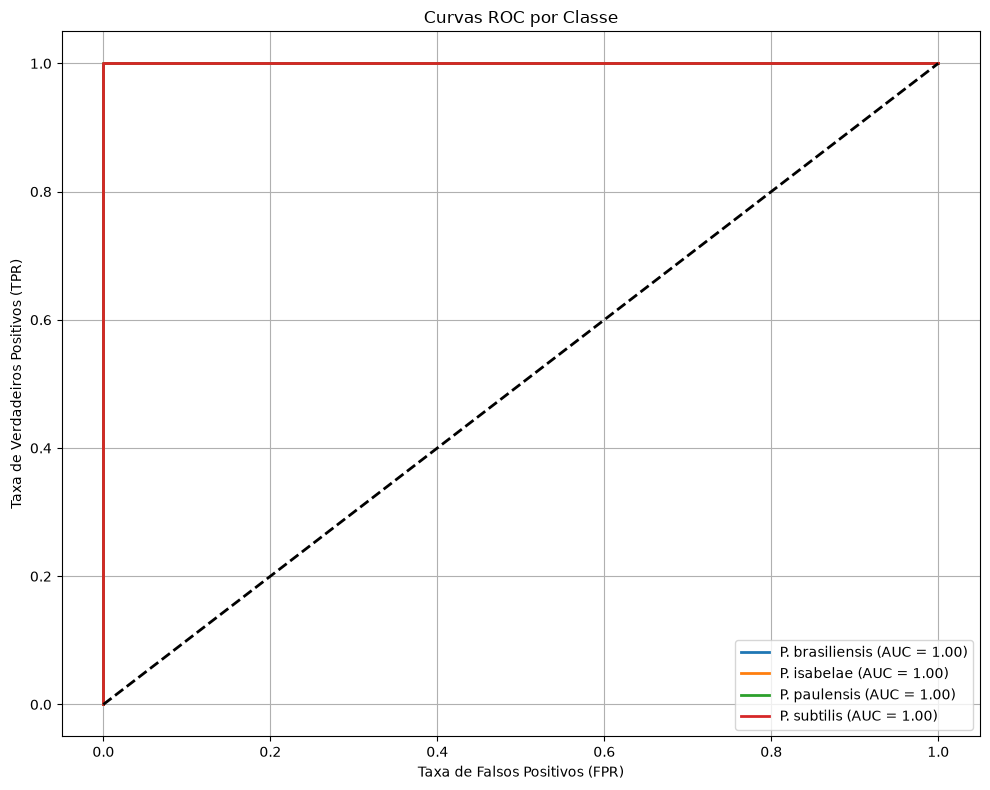

####################################################################################
Fold: 3 ----- Learning_rates: 0.0005

Acurácia final: 97.50%
F1-score macro: 0.97
F1-score weighted: 0.97

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        10
    P. isabelae       1.00      0.86      0.92         7
   P. paulensis       1.00      1.00      1.00        12
    P. subtilis       0.92      1.00      0.96        11

       accuracy                           0.97        40
      macro avg       0.98      0.96      0.97        40
   weighted avg       0.98      0.97      0.97        40



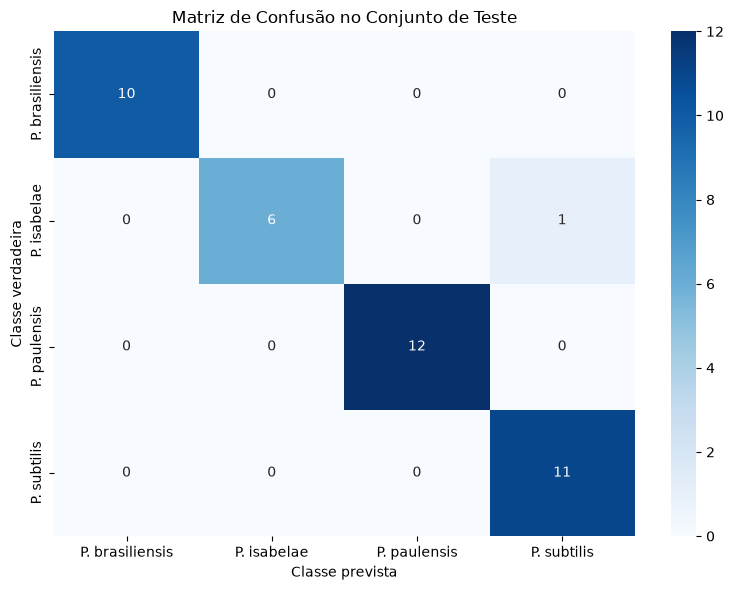

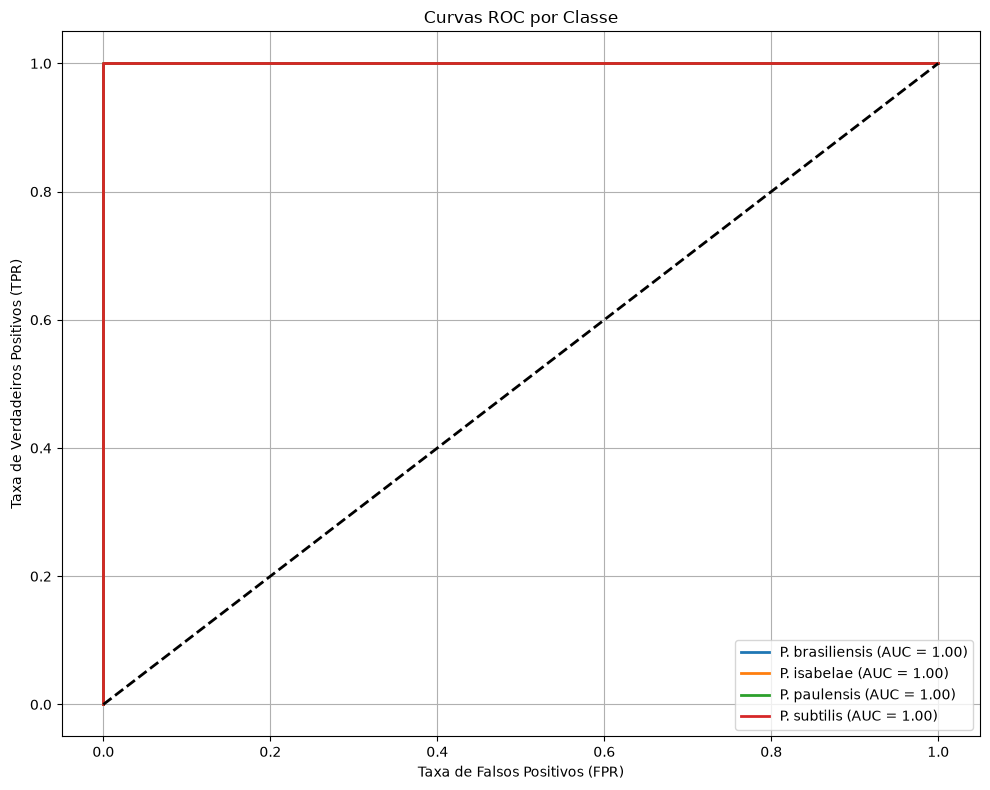

####################################################################################
Fold: 4 ----- Learning_rates: 0.0005

Acurácia final: 97.50%
F1-score macro: 0.98
F1-score weighted: 0.97

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        10
    P. isabelae       1.00      1.00      1.00         7
   P. paulensis       0.92      1.00      0.96        12
    P. subtilis       1.00      0.91      0.95        11

       accuracy                           0.97        40
      macro avg       0.98      0.98      0.98        40
   weighted avg       0.98      0.97      0.97        40



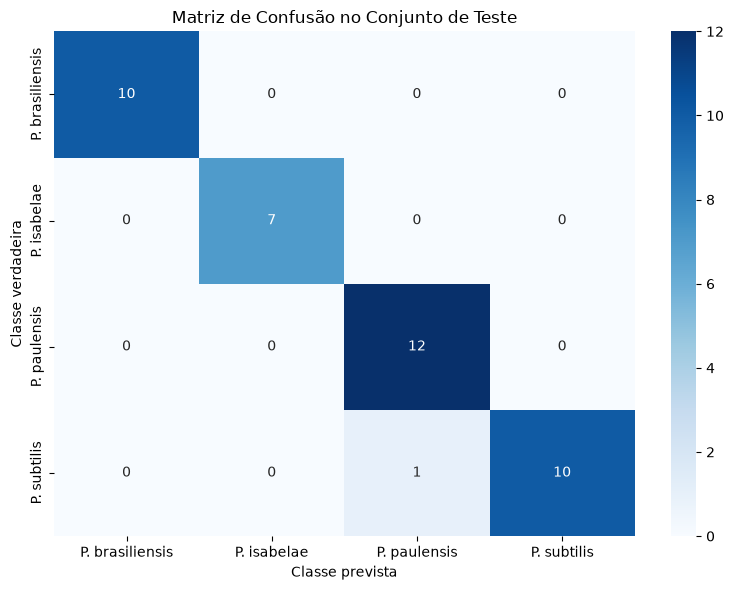

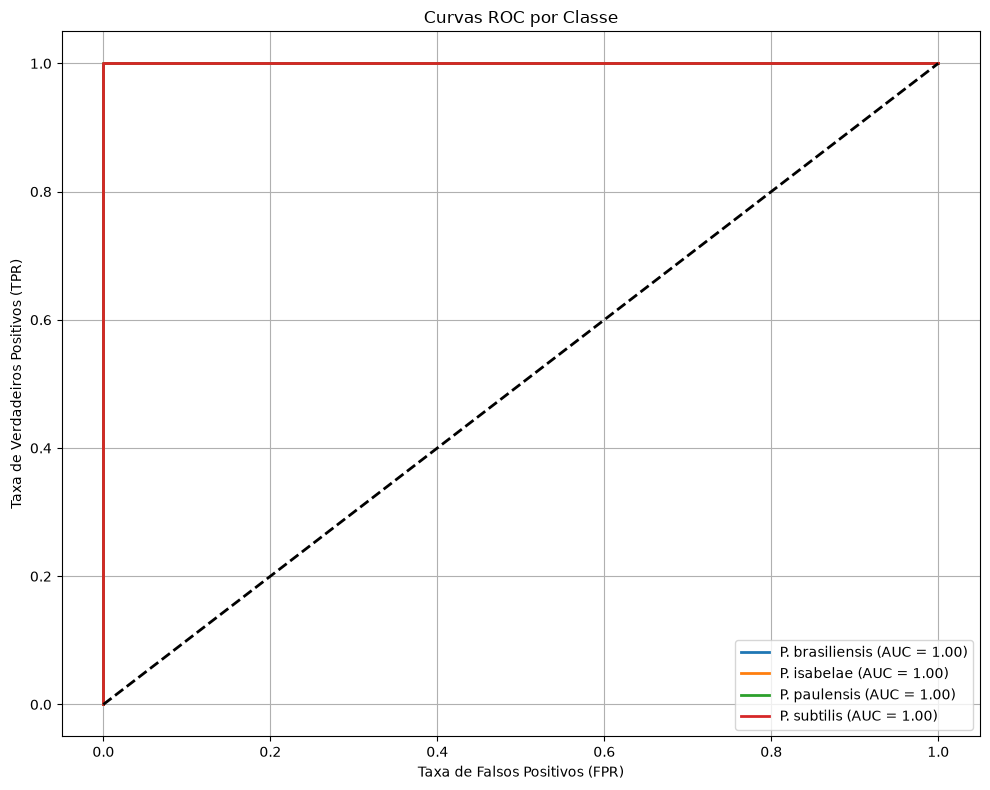

####################################################################################
Fold: 1 ----- Learning_rates: 0.0001

Acurácia final: 100.00%
F1-score macro: 1.00
F1-score weighted: 1.00

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        11
    P. isabelae       1.00      1.00      1.00         7
   P. paulensis       1.00      1.00      1.00        12
    P. subtilis       1.00      1.00      1.00        10

       accuracy                           1.00        40
      macro avg       1.00      1.00      1.00        40
   weighted avg       1.00      1.00      1.00        40



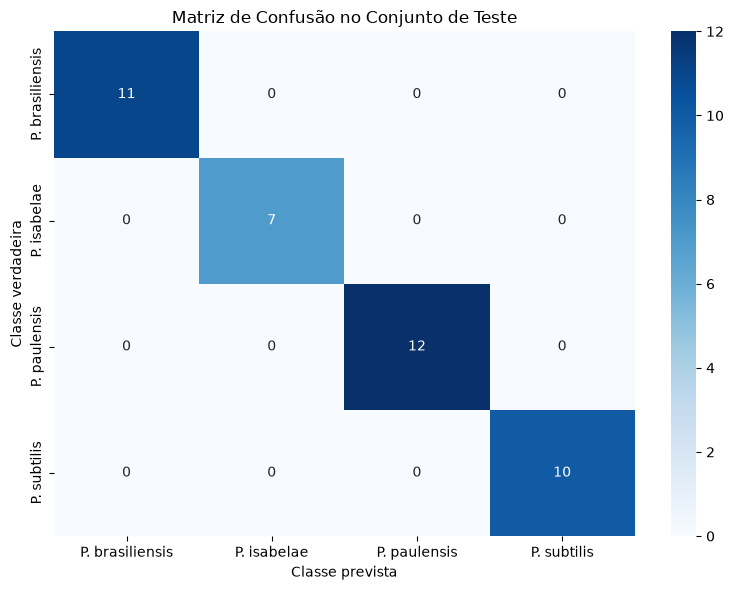

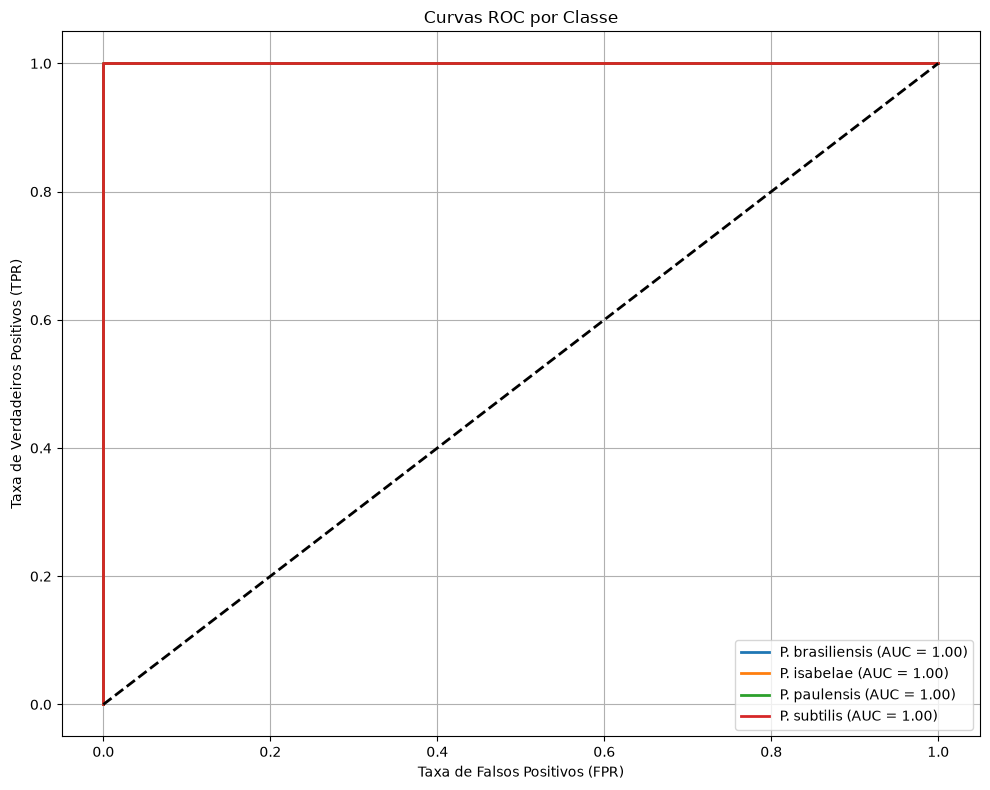

####################################################################################
Fold: 2 ----- Learning_rates: 0.0001

Acurácia final: 100.00%
F1-score macro: 1.00
F1-score weighted: 1.00

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        11
    P. isabelae       1.00      1.00      1.00         6
   P. paulensis       1.00      1.00      1.00        12
    P. subtilis       1.00      1.00      1.00        11

       accuracy                           1.00        40
      macro avg       1.00      1.00      1.00        40
   weighted avg       1.00      1.00      1.00        40



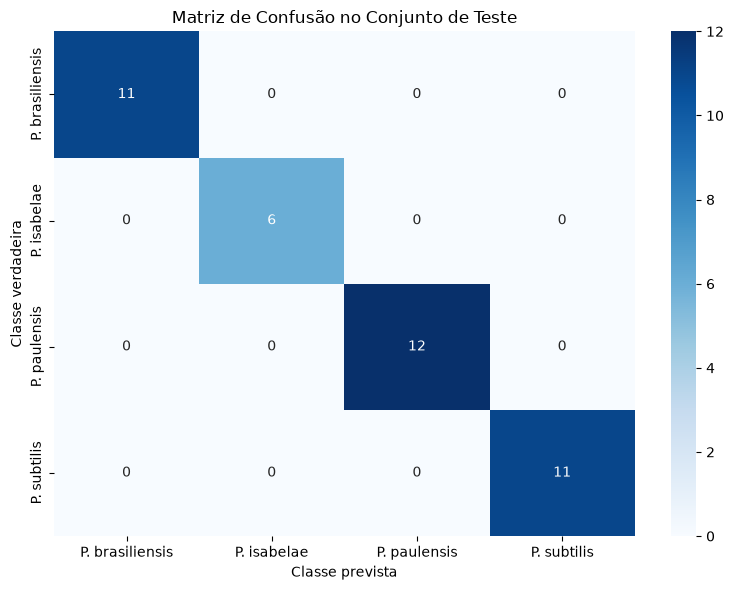

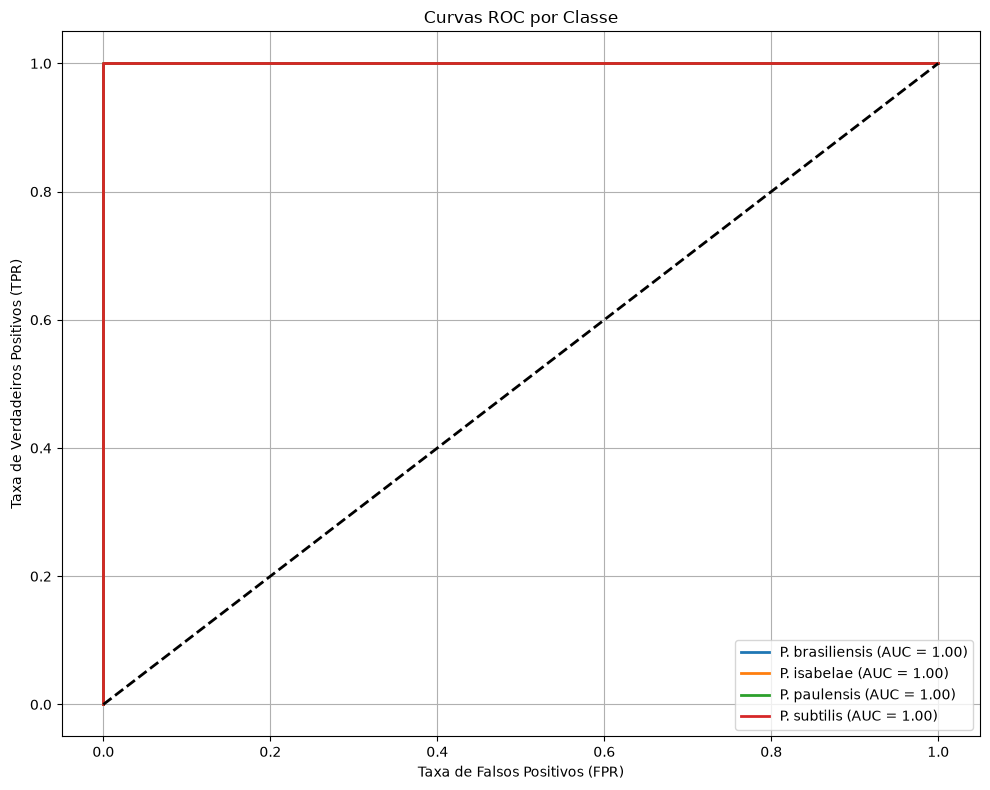

####################################################################################
Fold: 3 ----- Learning_rates: 0.0001

Acurácia final: 97.50%
F1-score macro: 0.97
F1-score weighted: 0.97

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        10
    P. isabelae       1.00      0.86      0.92         7
   P. paulensis       1.00      1.00      1.00        12
    P. subtilis       0.92      1.00      0.96        11

       accuracy                           0.97        40
      macro avg       0.98      0.96      0.97        40
   weighted avg       0.98      0.97      0.97        40



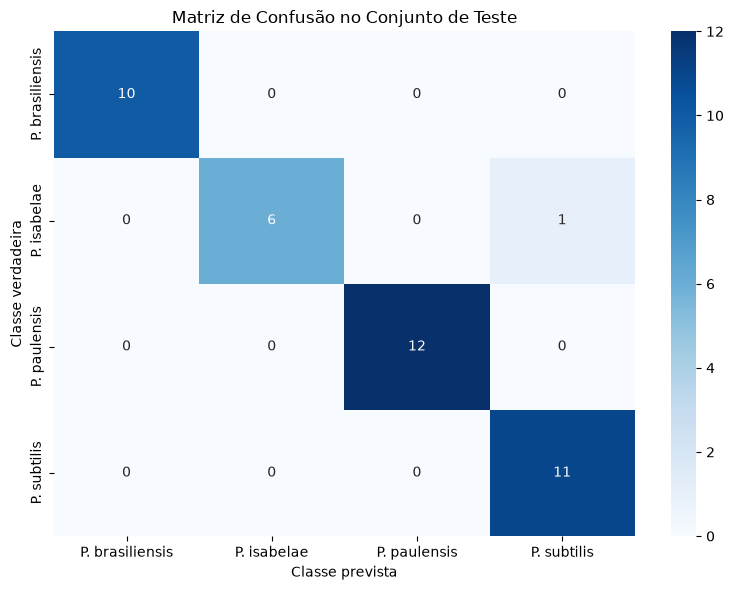

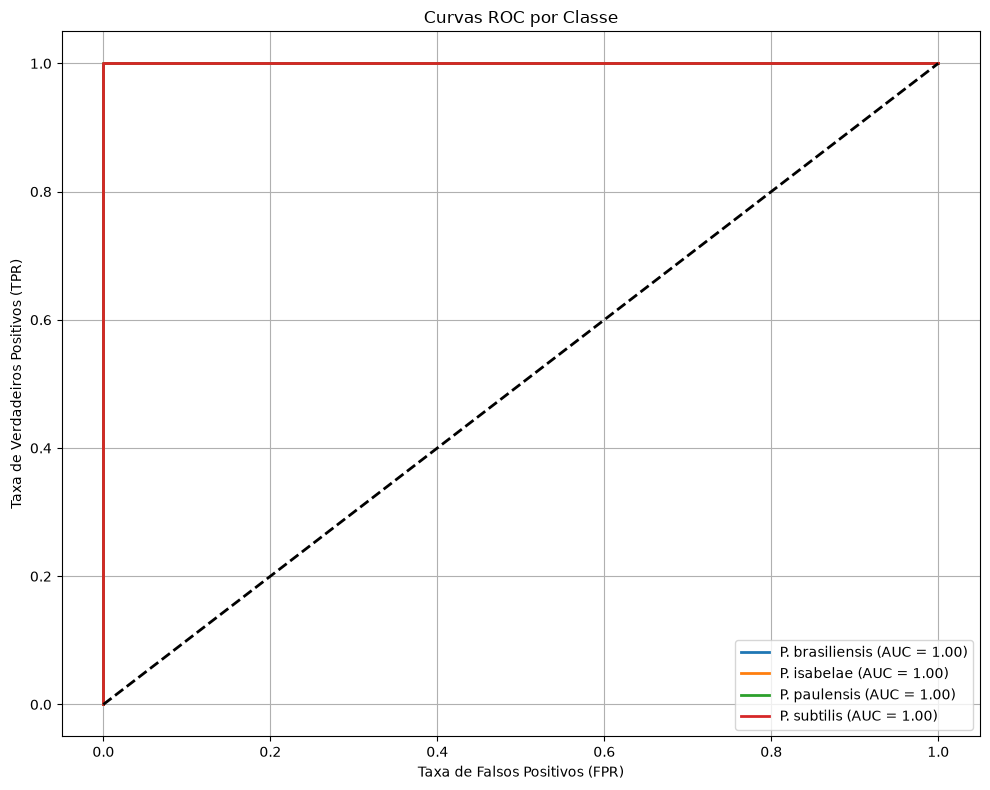

####################################################################################
Fold: 4 ----- Learning_rates: 0.0001

Acurácia final: 95.00%
F1-score macro: 0.95
F1-score weighted: 0.95

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        10
    P. isabelae       0.88      1.00      0.93         7
   P. paulensis       1.00      0.83      0.91        12
    P. subtilis       0.92      1.00      0.96        11

       accuracy                           0.95        40
      macro avg       0.95      0.96      0.95        40
   weighted avg       0.96      0.95      0.95        40



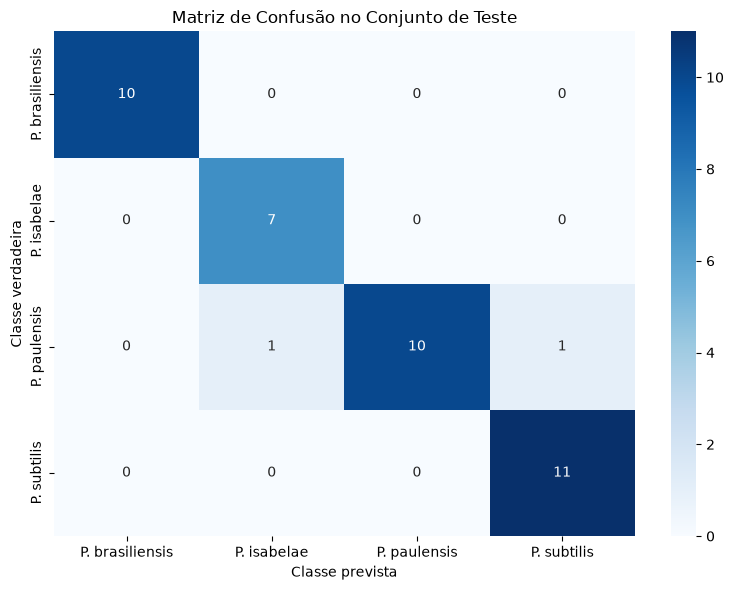

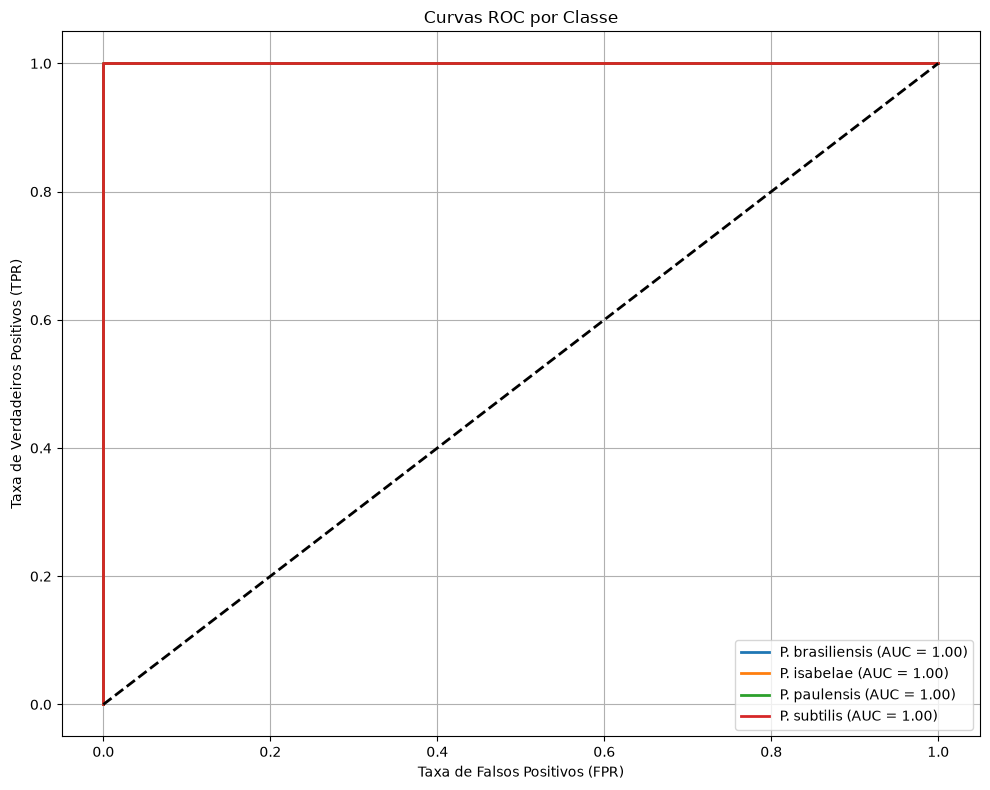

In [30]:
for lr in learning_rates:
    for fold in range(1,5):
        print("####################################################################################")
        print(f"Fold: {fold} ----- Learning_rates: {lr}")
        evaluate_model(classes_shrimp, cros_validation_history[lr].get_all_label_fold(fold),cros_validation_history[lr].get_all_pred_fold(fold), cros_validation_history[lr].get_all_prob_fold(fold) )

Busca de hiperparâmeotrs (Bath Size)

In [18]:
from sklearn.model_selection import StratifiedKFold, train_test_split

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# Valores para variação de hiperparâmetros
batch_sizes = [4, 8, 16]

for batch_size in batch_sizes:

    cros_validation_history[batch_size] = CrossValidationHistory()

    for fold, (train_idx, test_idx) in enumerate(
        skf.split(views_list_image_paths, labels_paths),
        start=1
    ):

        history = cros_validation_history[batch_size]

        print(f"\n Fold {fold} - bath_size {batch_size}")

        # Divide treino e teste do fold
        X_train = [views_list_image_paths[i] for i in train_idx]
        y_train = [labels_paths[i] for i in train_idx]

        X_val = [views_list_image_paths[i] for i in test_idx]
        y_val = [labels_paths[i] for i in test_idx]

        # Executa um fold completo
        loss, acc, f1 = run_fold(X_train, y_train, X_val,y_val, fold, history, batch_size=batch_size)
        
        history.add_fold(loss, acc, f1)

        # results.append(result)


 Fold 1 - bath_size 4
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 2 - bath_size 4
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 3 - bath_size 4
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (20 outputs left out)


 Fold 4 - bath_size 16
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 5 - bath_size 16
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



Acurácia final: 87.50%
F1-score macro: 0.88
F1-score weighted: 0.88

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.77      0.91      0.83        11
    P. isabelae       1.00      0.86      0.92         7
   P. paulensis       0.92      0.92      0.92        12
    P. subtilis       0.89      0.80      0.84        10

       accuracy                           0.88        40
      macro avg       0.89      0.87      0.88        40
   weighted avg       0.88      0.88      0.88        40



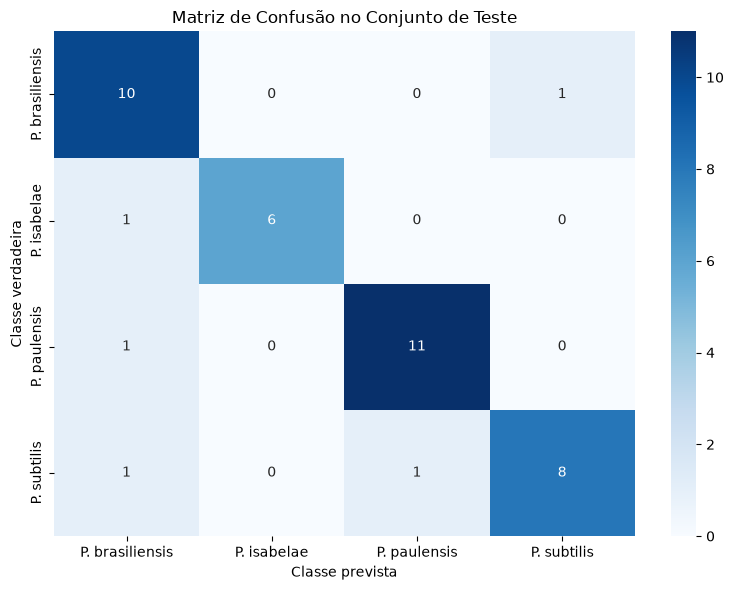

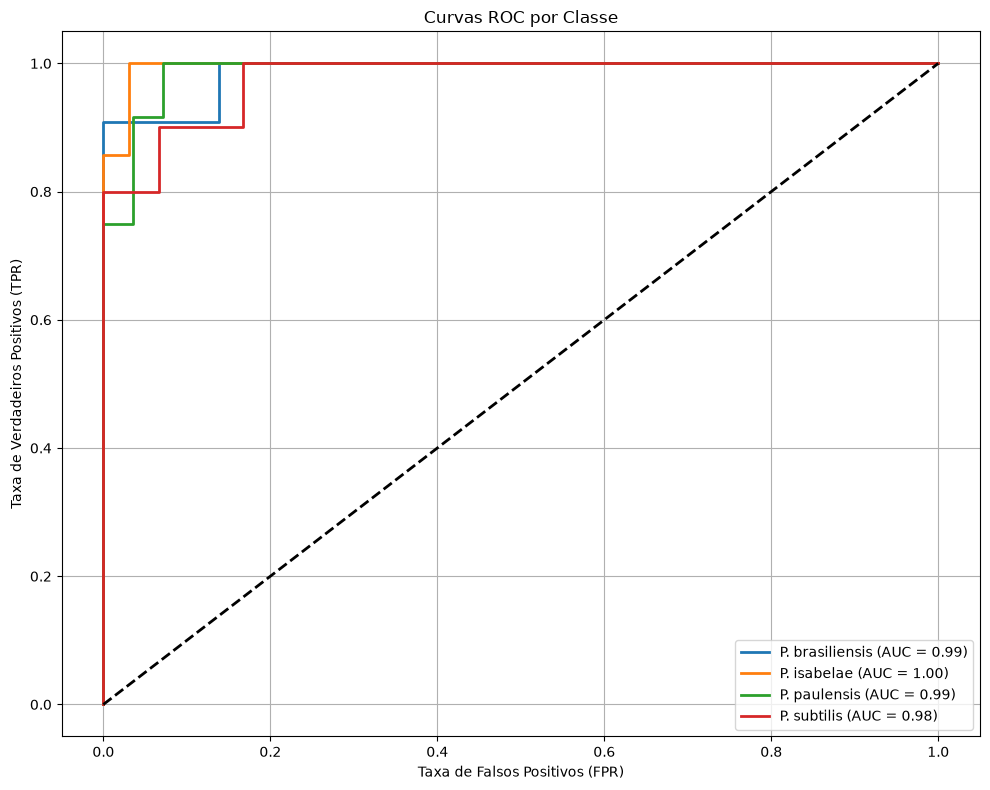


Acurácia final: 92.50%
F1-score macro: 0.93
F1-score weighted: 0.92

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.91      0.95        11
    P. isabelae       0.86      1.00      0.92         6
   P. paulensis       0.91      0.83      0.87        12
    P. subtilis       0.92      1.00      0.96        11

       accuracy                           0.93        40
      macro avg       0.92      0.94      0.93        40
   weighted avg       0.93      0.93      0.92        40



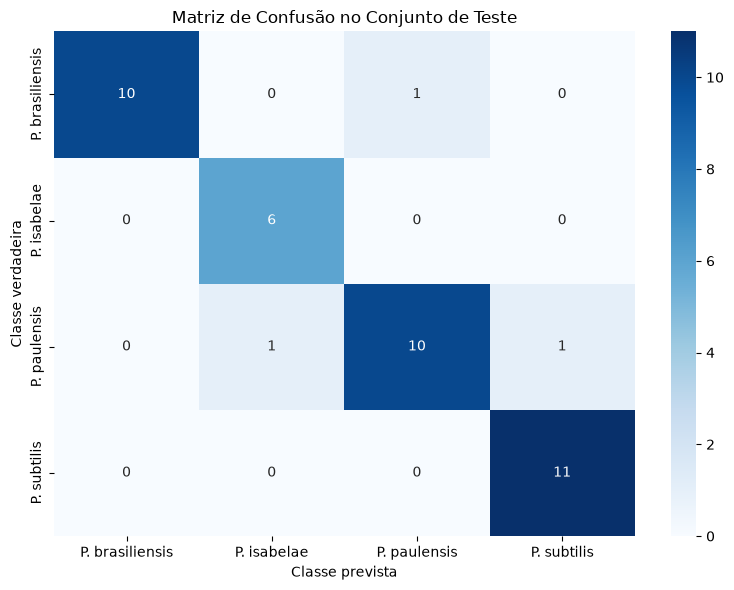

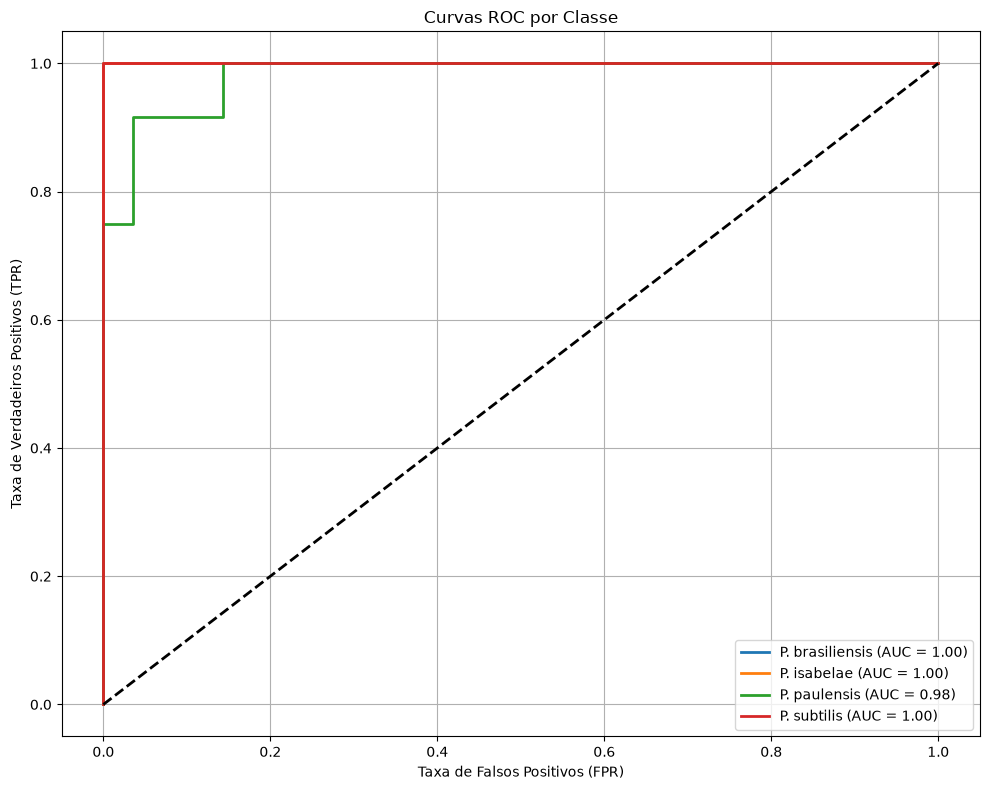


Acurácia final: 85.00%
F1-score macro: 0.84
F1-score weighted: 0.85

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.90      0.95        10
    P. isabelae       1.00      0.57      0.73         7
   P. paulensis       0.73      0.92      0.81        12
    P. subtilis       0.83      0.91      0.87        11

       accuracy                           0.85        40
      macro avg       0.89      0.82      0.84        40
   weighted avg       0.87      0.85      0.85        40



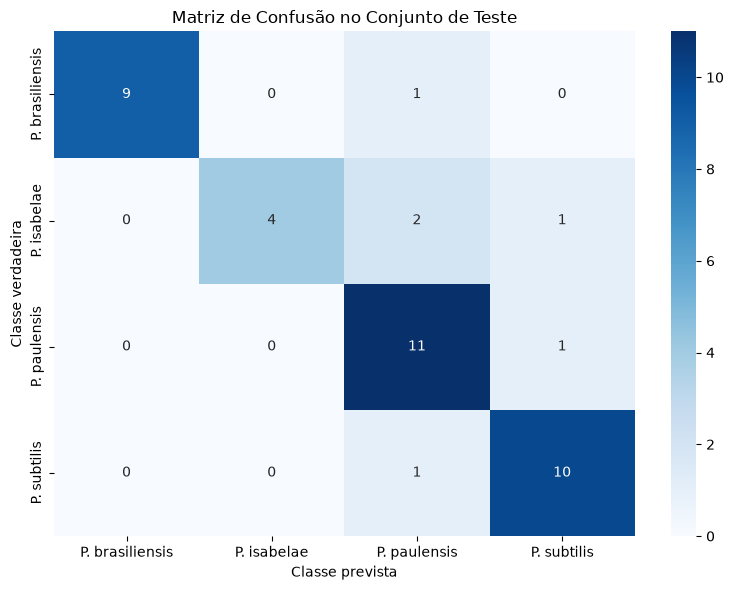

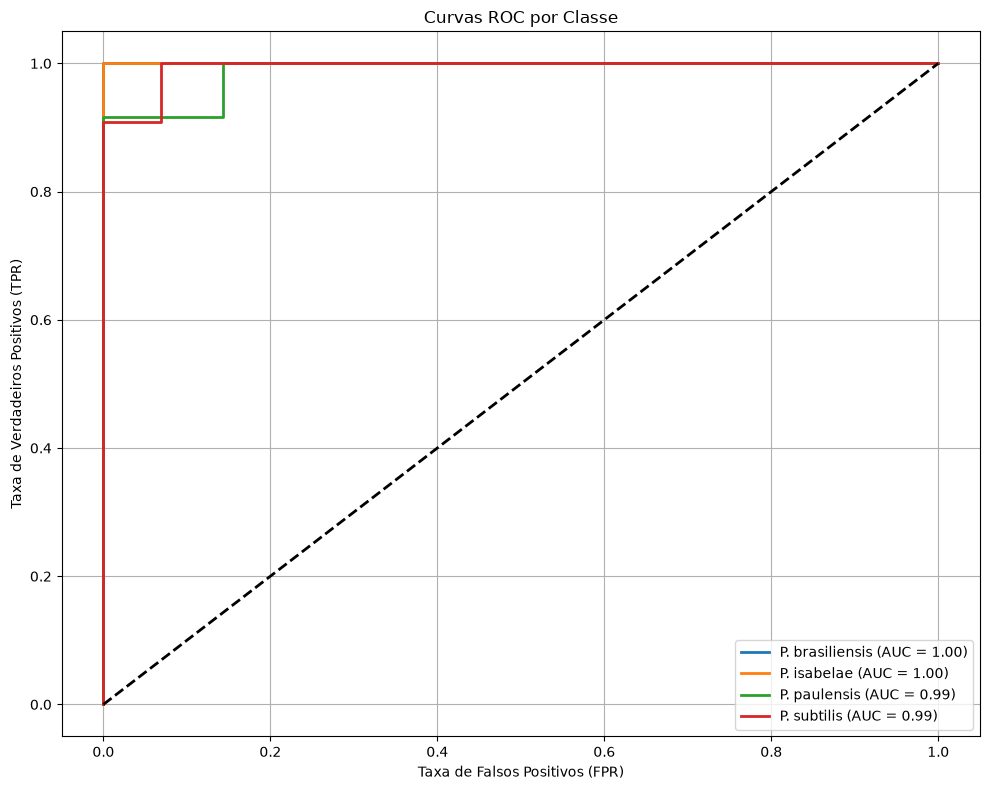


Acurácia final: 37.50%
F1-score macro: 0.31
F1-score weighted: 0.29

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.80      0.89        10
    P. isabelae       0.22      1.00      0.36         7
   P. paulensis       0.00      0.00      0.00        12
    P. subtilis       0.00      0.00      0.00        11

       accuracy                           0.38        40
      macro avg       0.30      0.45      0.31        40
   weighted avg       0.29      0.38      0.29        40



c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

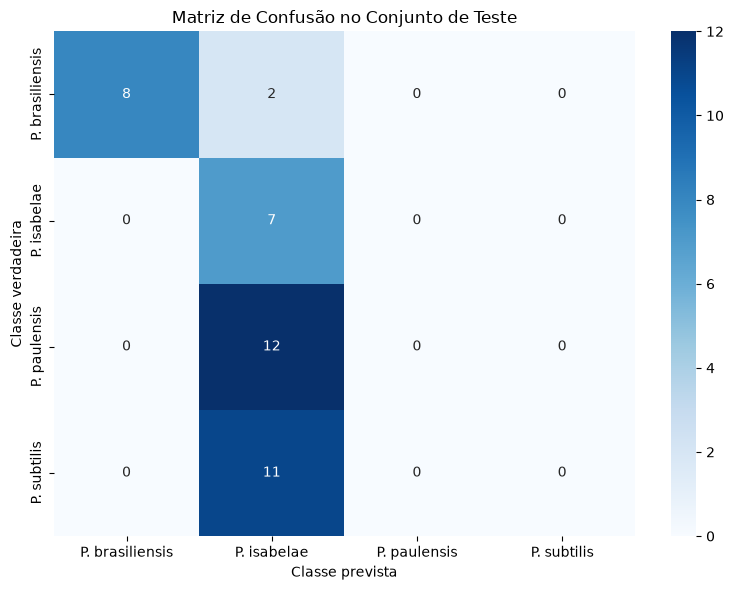

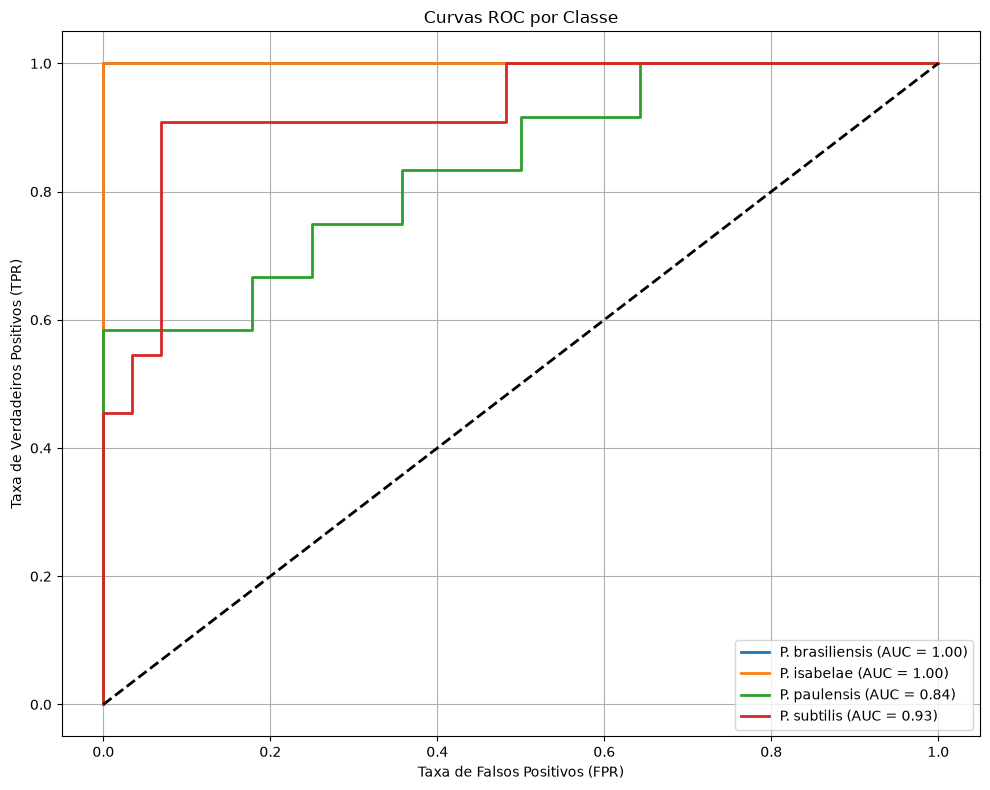


Acurácia final: 50.00%
F1-score macro: 0.52
F1-score weighted: 0.52

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.55      0.71        11
    P. isabelae       0.27      1.00      0.42         7
   P. paulensis       0.67      0.17      0.27        12
    P. subtilis       1.00      0.50      0.67        10

       accuracy                           0.50        40
      macro avg       0.73      0.55      0.52        40
   weighted avg       0.77      0.50      0.52        40



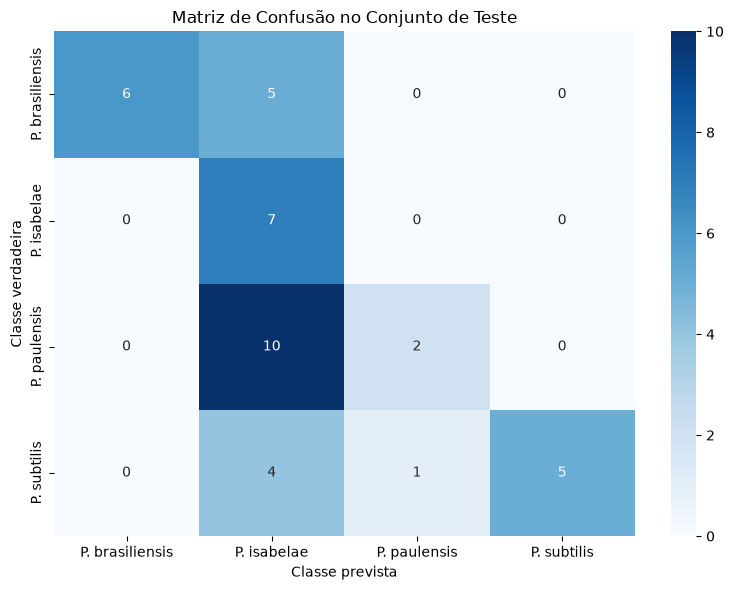

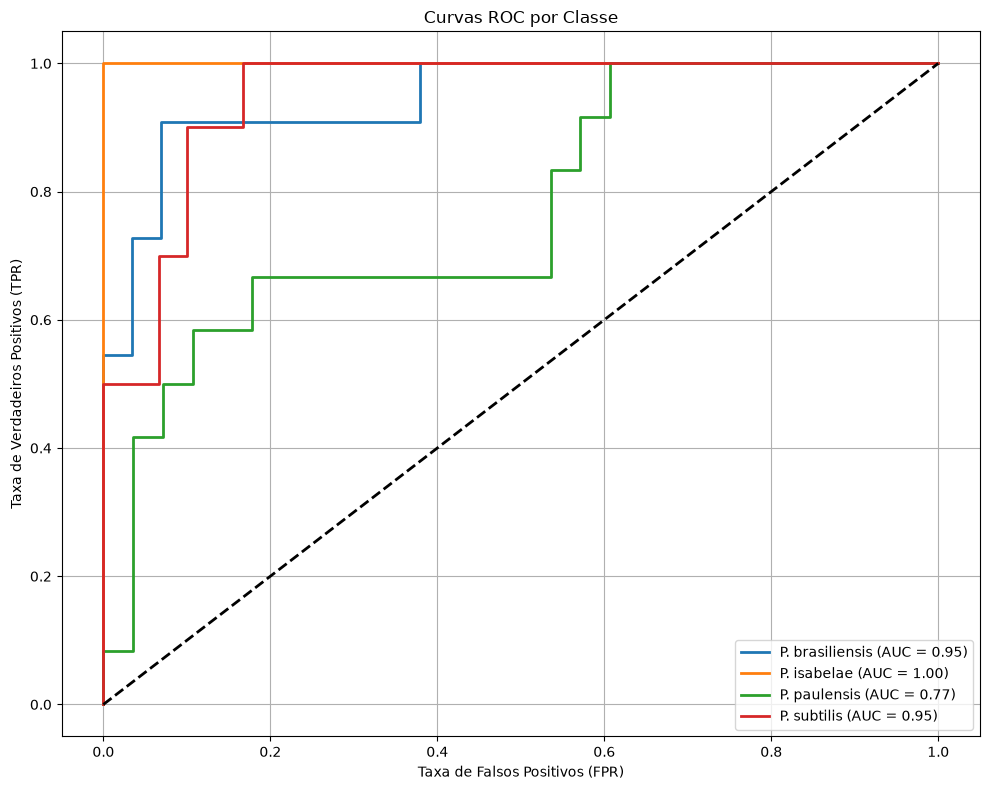


Acurácia final: 75.00%
F1-score macro: 0.74
F1-score weighted: 0.75

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.45      0.62        11
    P. isabelae       0.43      1.00      0.60         6
   P. paulensis       1.00      0.67      0.80        12
    P. subtilis       0.85      1.00      0.92        11

       accuracy                           0.75        40
      macro avg       0.82      0.78      0.74        40
   weighted avg       0.87      0.75      0.75        40



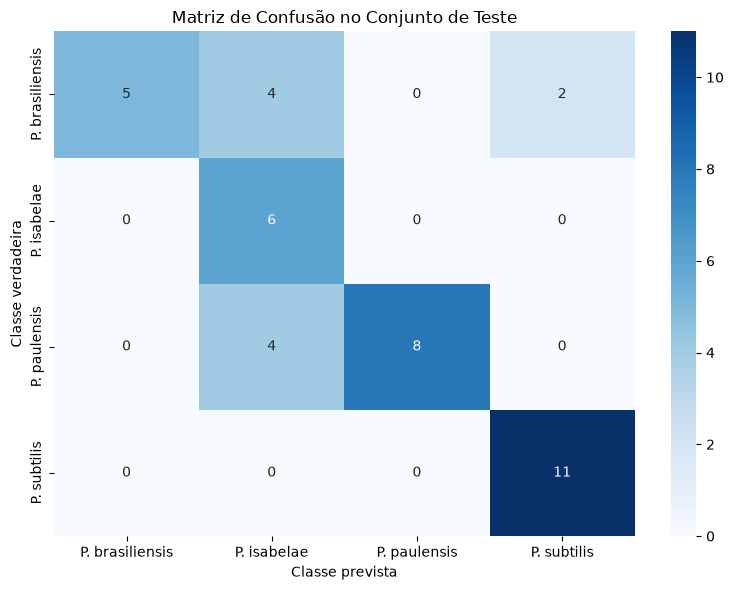

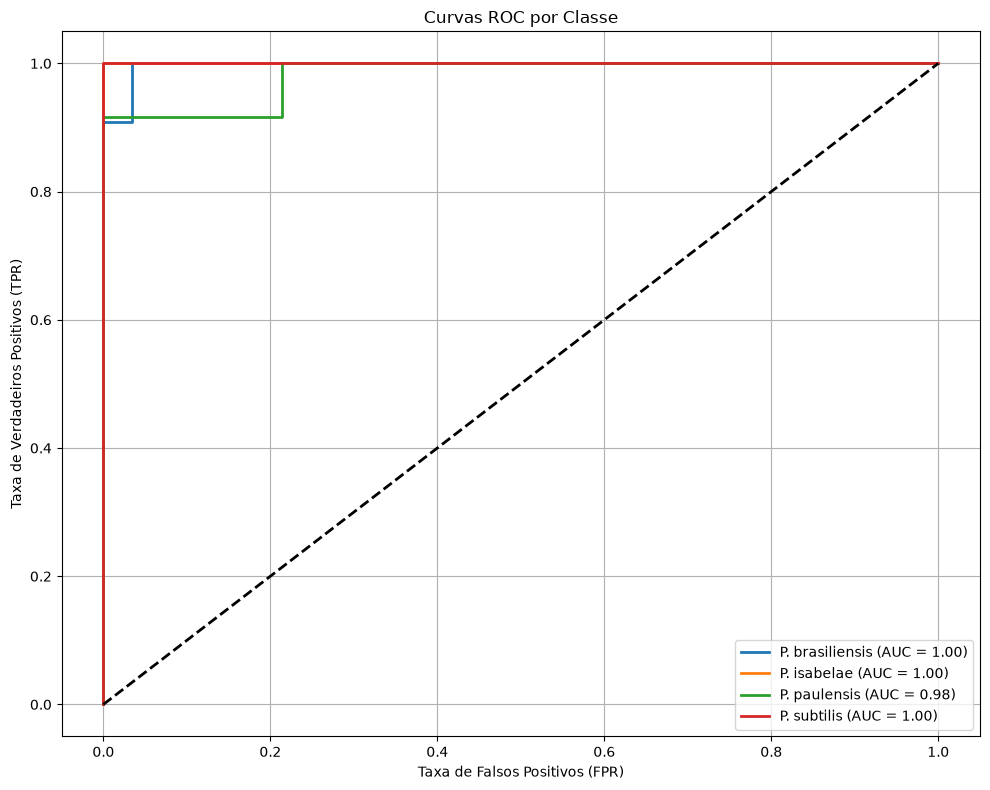


Acurácia final: 82.50%
F1-score macro: 0.80
F1-score weighted: 0.81

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.50      0.67        10
    P. isabelae       0.83      0.71      0.77         7
   P. paulensis       0.75      1.00      0.86        12
    P. subtilis       0.85      1.00      0.92        11

       accuracy                           0.82        40
      macro avg       0.86      0.80      0.80        40
   weighted avg       0.85      0.82      0.81        40



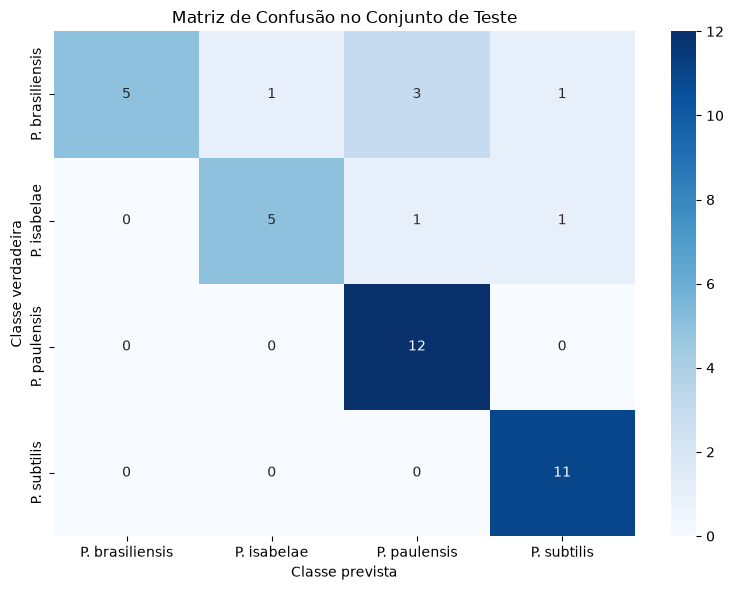

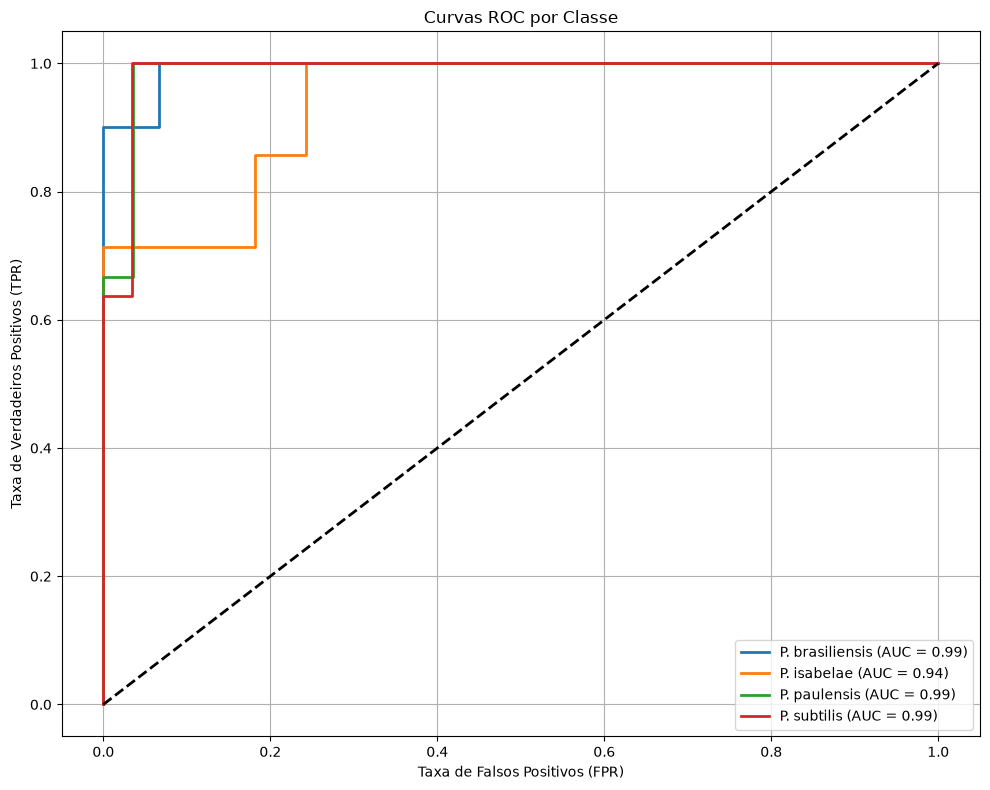


Acurácia final: 95.00%
F1-score macro: 0.96
F1-score weighted: 0.95

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.90      0.95        10
    P. isabelae       1.00      1.00      1.00         7
   P. paulensis       0.86      1.00      0.92        12
    P. subtilis       1.00      0.91      0.95        11

       accuracy                           0.95        40
      macro avg       0.96      0.95      0.96        40
   weighted avg       0.96      0.95      0.95        40



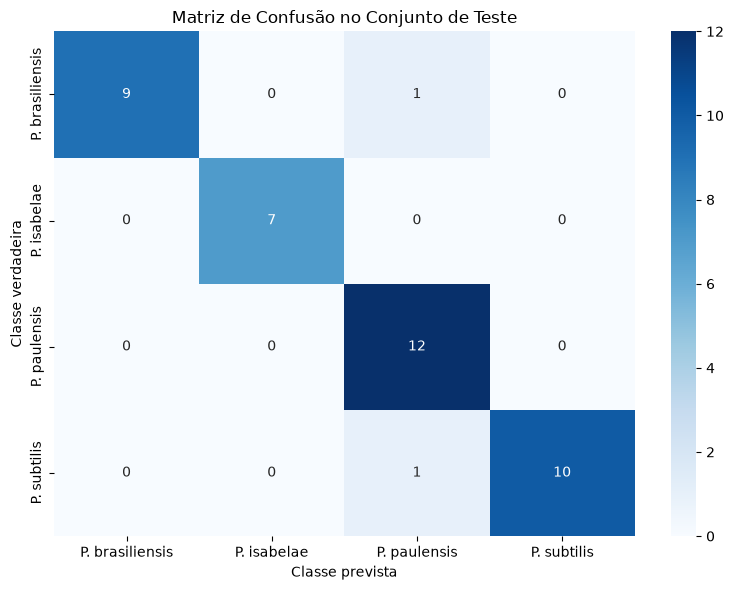

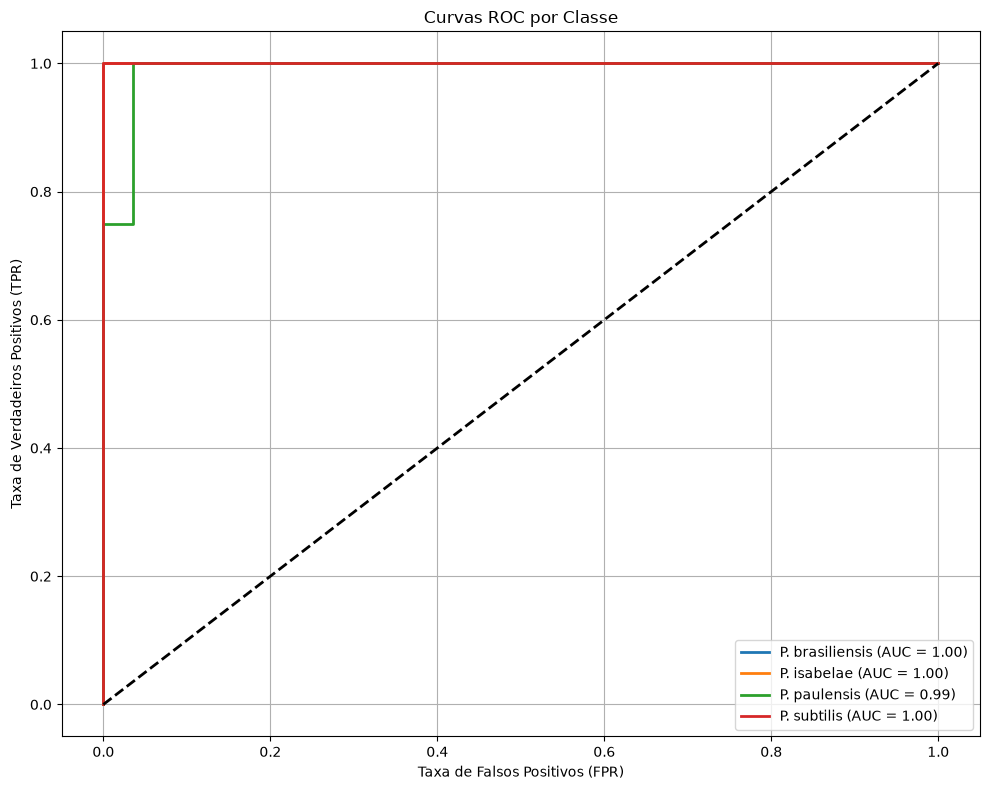


Acurácia final: 95.00%
F1-score macro: 0.95
F1-score weighted: 0.95

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        11
    P. isabelae       1.00      0.86      0.92         7
   P. paulensis       1.00      0.92      0.96        12
    P. subtilis       0.83      1.00      0.91        10

       accuracy                           0.95        40
      macro avg       0.96      0.94      0.95        40
   weighted avg       0.96      0.95      0.95        40



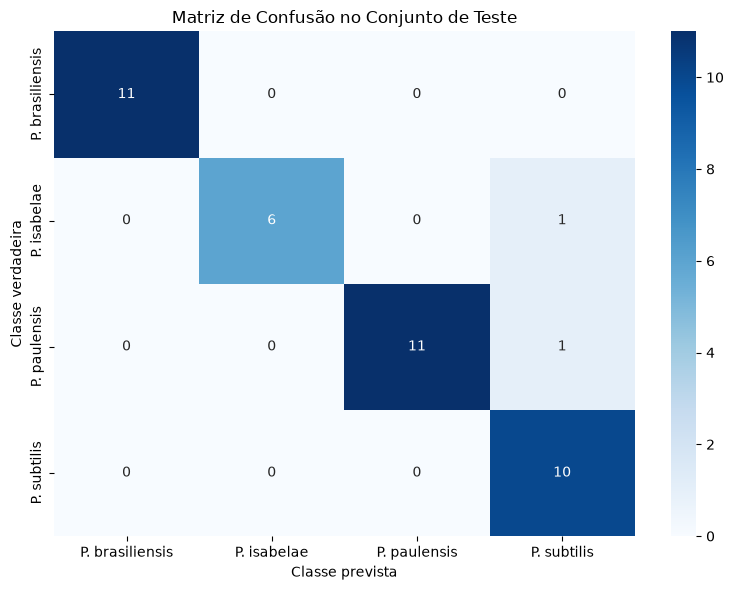

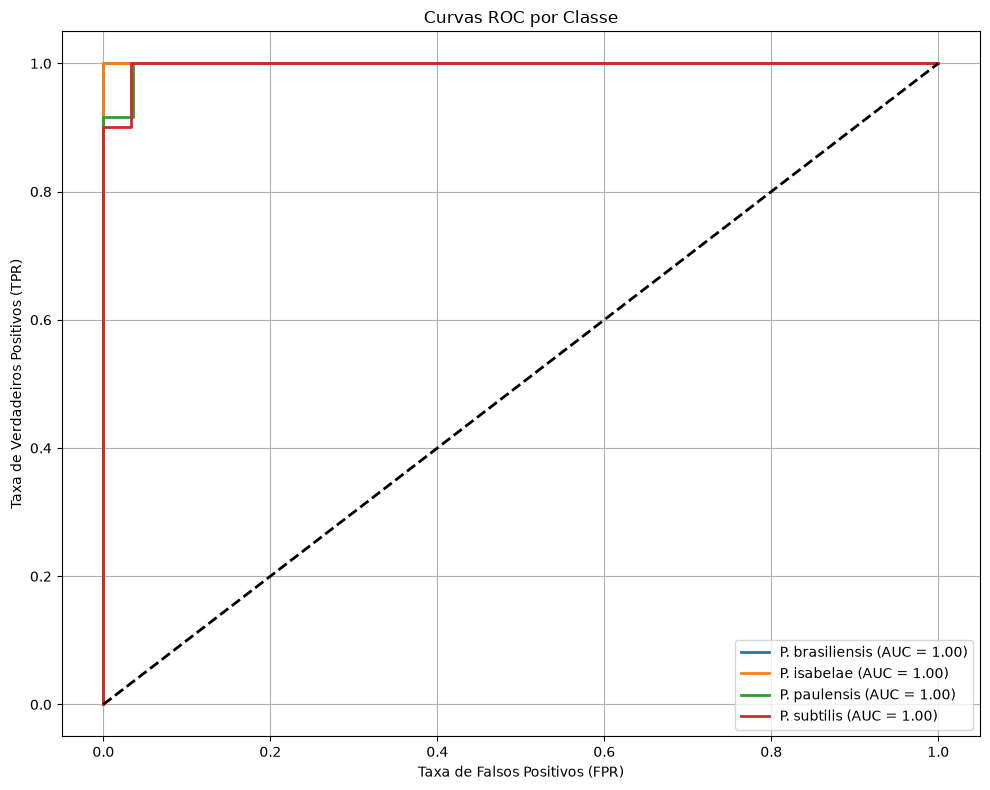


Acurácia final: 97.50%
F1-score macro: 0.97
F1-score weighted: 0.98

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        11
    P. isabelae       0.86      1.00      0.92         6
   P. paulensis       1.00      0.92      0.96        12
    P. subtilis       1.00      1.00      1.00        11

       accuracy                           0.97        40
      macro avg       0.96      0.98      0.97        40
   weighted avg       0.98      0.97      0.98        40



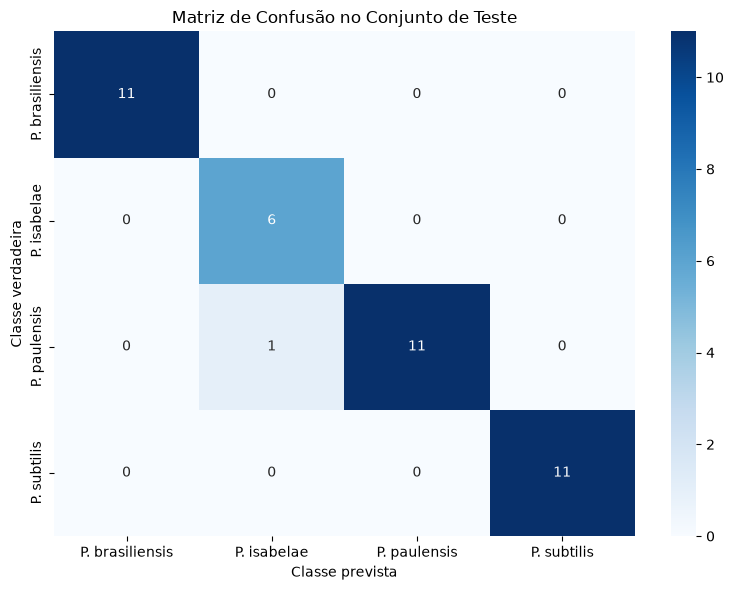

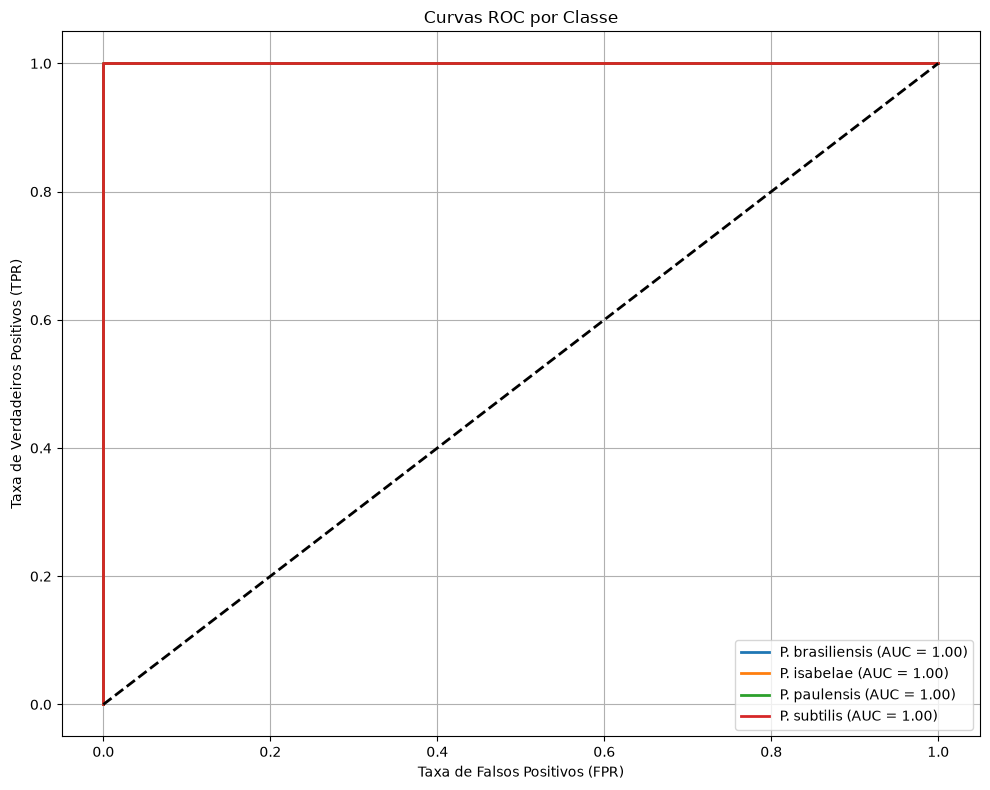


Acurácia final: 92.50%
F1-score macro: 0.92
F1-score weighted: 0.93

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.90      0.95        10
    P. isabelae       0.86      0.86      0.86         7
   P. paulensis       0.85      0.92      0.88        12
    P. subtilis       1.00      1.00      1.00        11

       accuracy                           0.93        40
      macro avg       0.93      0.92      0.92        40
   weighted avg       0.93      0.93      0.93        40



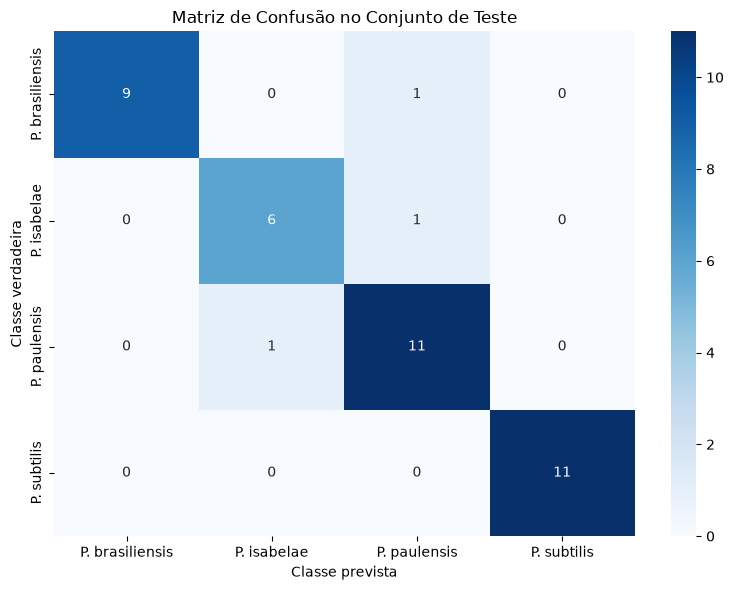

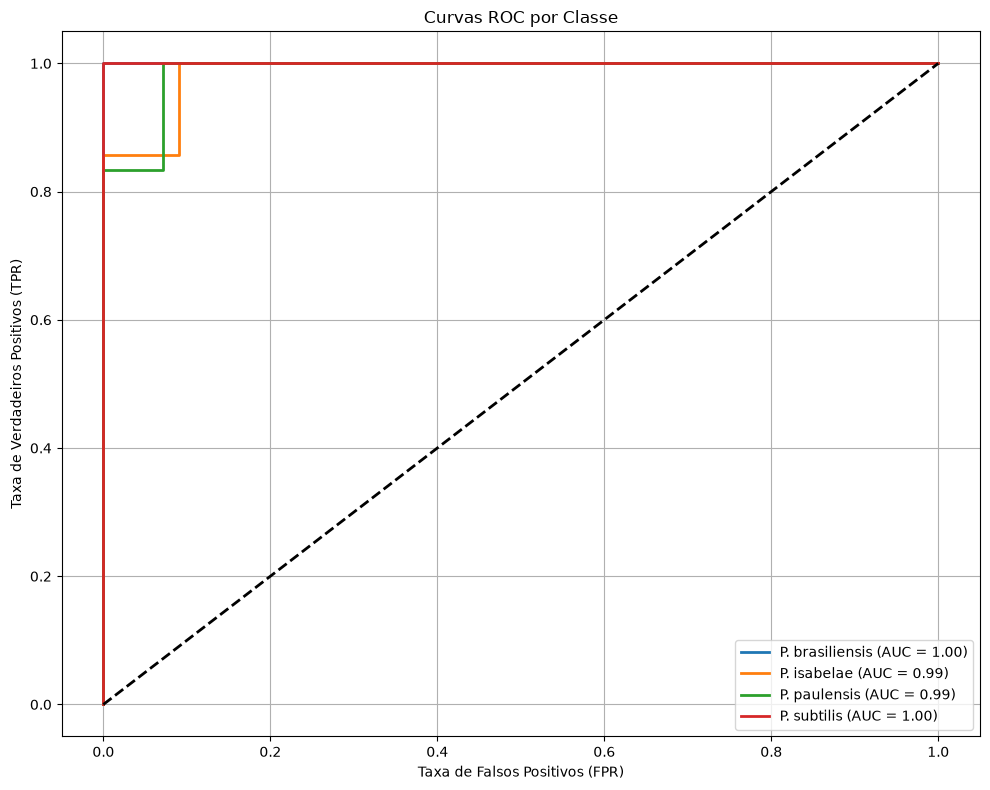


Acurácia final: 85.00%
F1-score macro: 0.85
F1-score weighted: 0.85

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.70      0.82        10
    P. isabelae       0.88      1.00      0.93         7
   P. paulensis       0.82      0.75      0.78        12
    P. subtilis       0.79      1.00      0.88        11

       accuracy                           0.85        40
      macro avg       0.87      0.86      0.85        40
   weighted avg       0.86      0.85      0.85        40



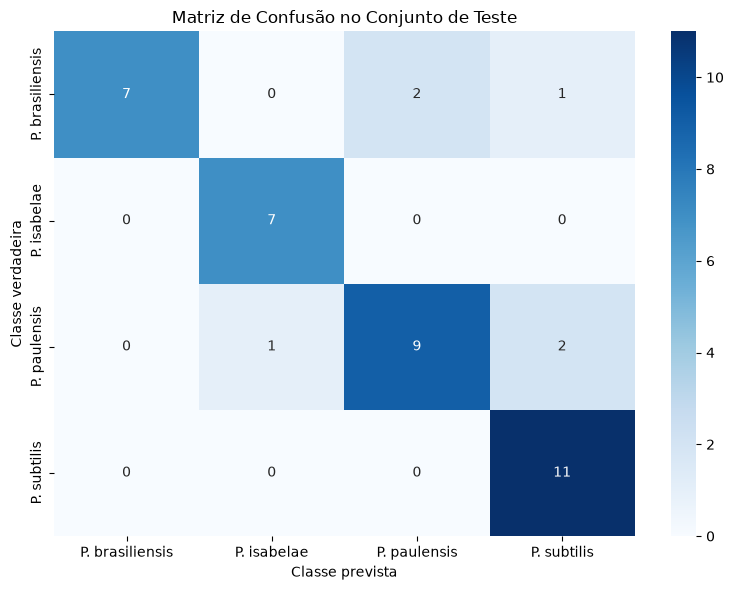

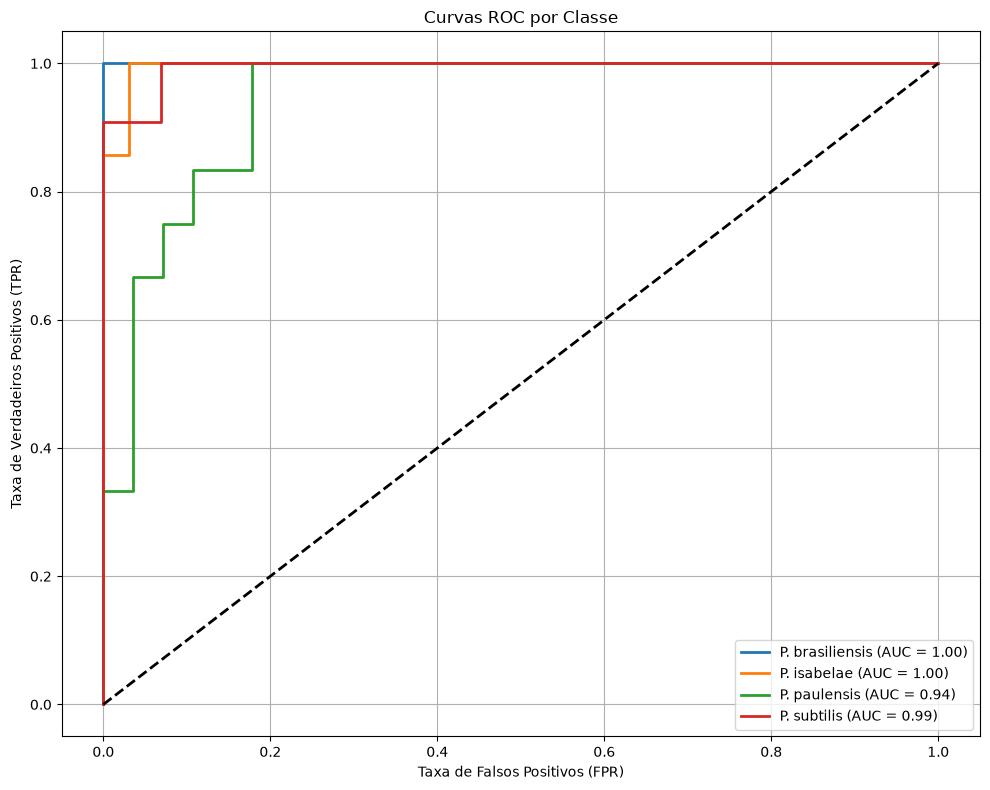

In [ ]:
for batch_size in batch_sizes: 
    for fold in range(1,5):
        print("####################################################################################")
        print(f"Fold: {fold} | Batch_size: {batch_size}")
        evaluate_model(classes_shrimp, cros_validation_history[batch_size].get_all_label_fold(fold),cros_validation_history[batch_size].get_all_pred_fold(fold), cros_validation_history[batch_size].get_all_prob_fold(fold) )

Busca de hiperparâmeotrs (Pooling)

In [22]:
from sklearn.model_selection import StratifiedKFold, train_test_split

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# Valores para variação de hiperparâmetros
poolings = [
    nn.AdaptiveMaxPool1d(1), 
    nn.AdaptiveAvgPool1d(1)
]

for pooling in poolings:

    cros_validation_history[pooling] = CrossValidationHistory()

    for fold, (train_idx, test_idx) in enumerate(
        skf.split(views_list_image_paths, labels_paths),
        start=1
    ):

        history = cros_validation_history[pooling]

        print(f"\n Fold {fold} - pooling {pooling}")

        # Divide treino e teste do fold
        X_train = [views_list_image_paths[i] for i in train_idx]
        y_train = [labels_paths[i] for i in train_idx]

        X_val = [views_list_image_paths[i] for i in test_idx]
        y_val = [labels_paths[i] for i in test_idx]

        # Executa um fold completo
        loss, acc, f1 = run_fold(X_train, y_train, X_val,y_val, fold, history, pooling=pooling)
        
        history.add_fold(loss, acc, f1)

        # results.append(result)


 Fold 1 - pooling AdaptiveMaxPool1d(output_size=1)
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 2 - pooling AdaptiveMaxPool1d(output_size=1)
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 3 - pooling AdaptiveMaxPool1d(output_size=1)
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 4 - pooling AdaptiveMaxPool1d(output_size=1)
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 5 - pooling AdaptiveMaxPool1d(output_size=1)
cuda


c:\Users\USUARIO\Documents\camarao_rosa_mvcnn\venv\Lib\site-packages\torch\autograd\graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:164.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass



 Fold 1 - pooling AdaptiveAvgPool1d(output_size=1)
cuda

 Fold 2 - pooling AdaptiveAvgPool1d(output_size=1)
cuda

 Fold 3 - pooling AdaptiveAvgPool1d(output_size=1)
cuda

 Fold 4 - pooling AdaptiveAvgPool1d(output_size=1)
cuda

 Fold 5 - pooling AdaptiveAvgPool1d(output_size=1)
cuda


####################################################################################
Fold: 1 | Pooling: AdaptiveMaxPool1d(output_size=1)

Acurácia final: 82.50%
F1-score macro: 0.84
F1-score weighted: 0.83

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.73      0.84        11
    P. isabelae       1.00      0.86      0.92         7
   P. paulensis       0.75      0.75      0.75        12
    P. subtilis       0.71      1.00      0.83        10

       accuracy                           0.82        40
      macro avg       0.87      0.83      0.84        40
   weighted avg       0.85      0.82      0.83        40



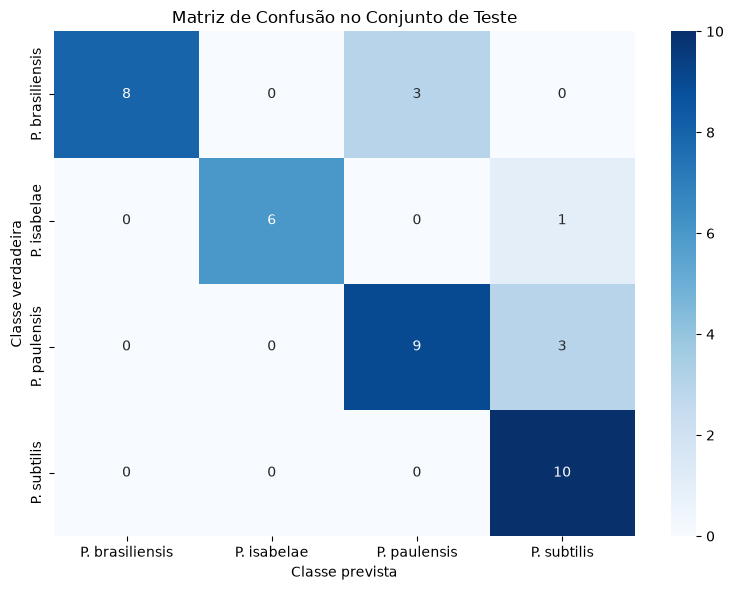

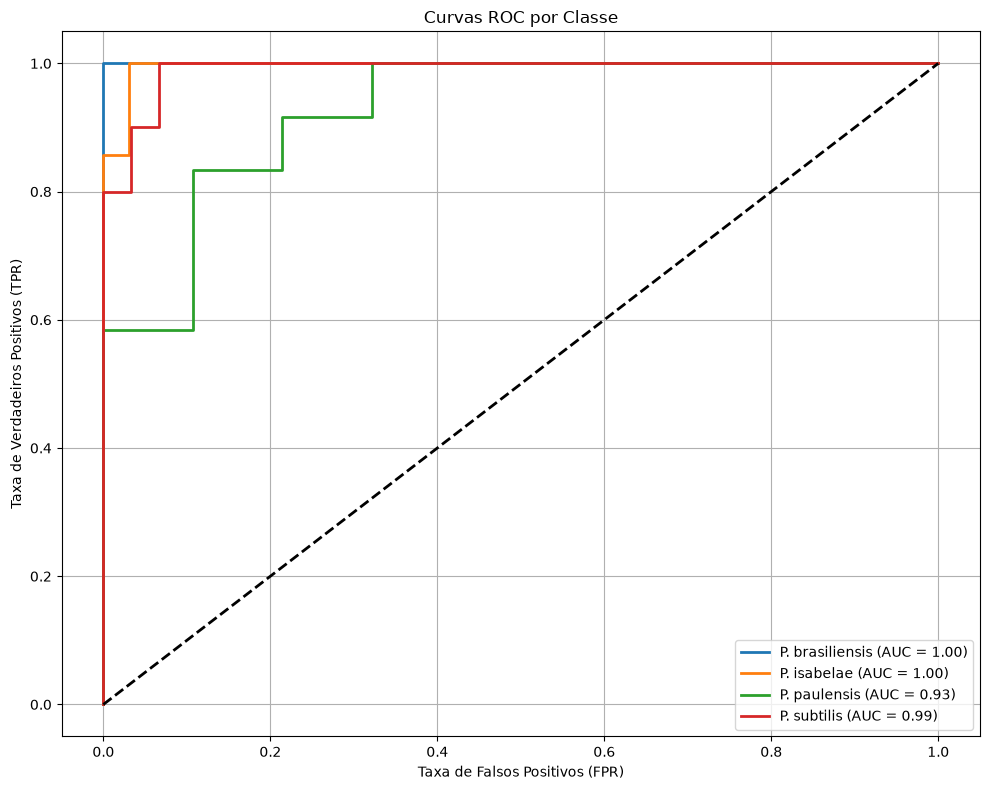

####################################################################################
Fold: 2 | Pooling: AdaptiveMaxPool1d(output_size=1)

Acurácia final: 82.50%
F1-score macro: 0.83
F1-score weighted: 0.82

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.55      0.71        11
    P. isabelae       1.00      0.83      0.91         6
   P. paulensis       0.79      0.92      0.85        12
    P. subtilis       0.73      1.00      0.85        11

       accuracy                           0.82        40
      macro avg       0.88      0.82      0.83        40
   weighted avg       0.86      0.82      0.82        40



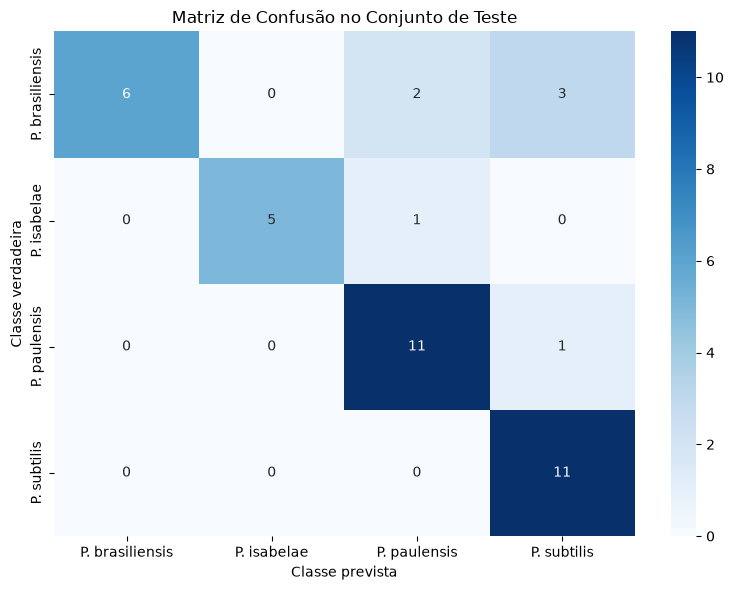

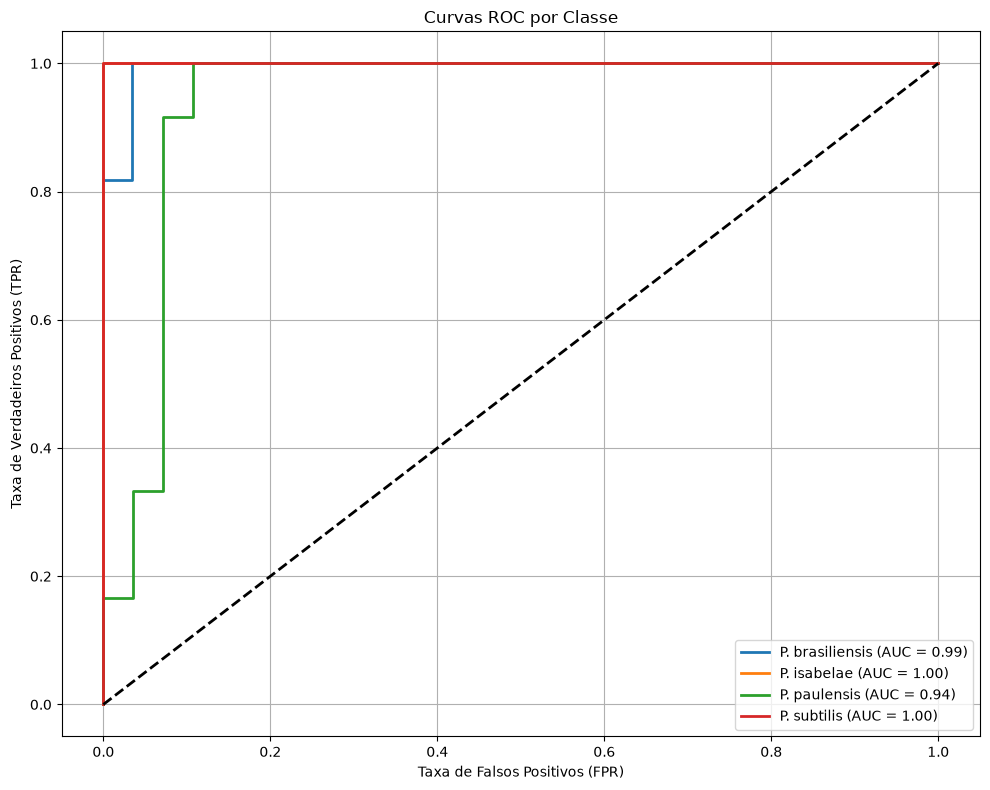

####################################################################################
Fold: 3 | Pooling: AdaptiveMaxPool1d(output_size=1)

Acurácia final: 95.00%
F1-score macro: 0.94
F1-score weighted: 0.95

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        10
    P. isabelae       1.00      0.71      0.83         7
   P. paulensis       1.00      1.00      1.00        12
    P. subtilis       0.85      1.00      0.92        11

       accuracy                           0.95        40
      macro avg       0.96      0.93      0.94        40
   weighted avg       0.96      0.95      0.95        40



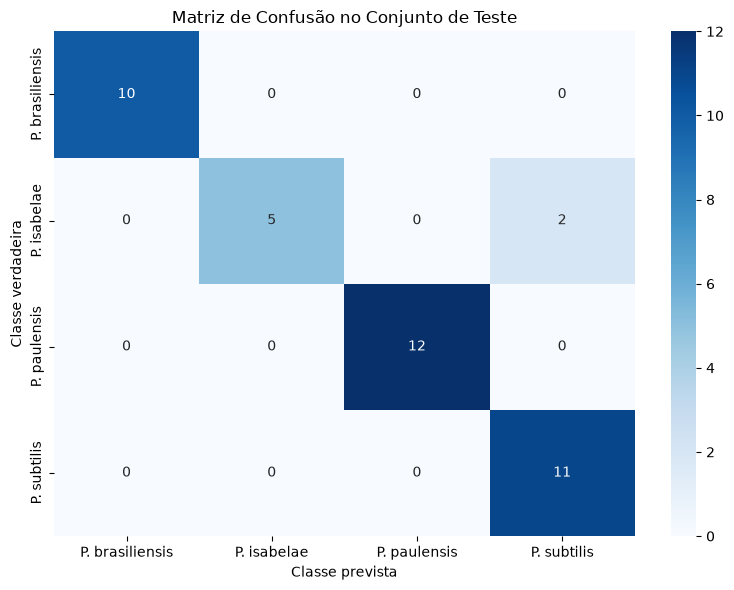

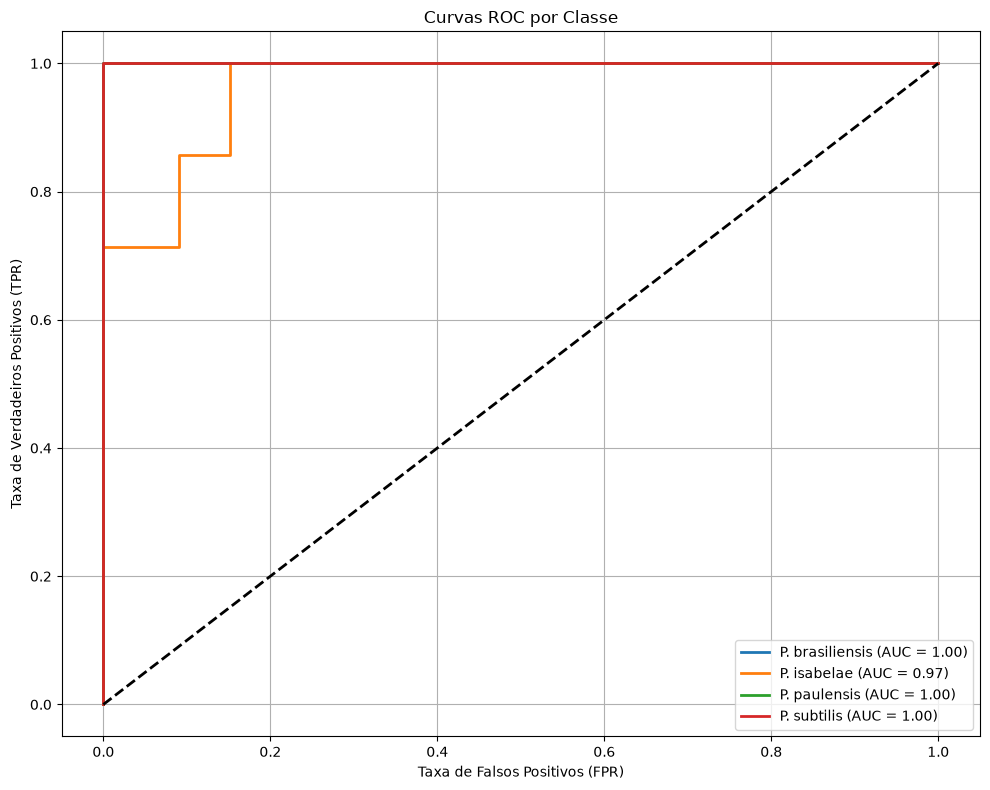

####################################################################################
Fold: 4 | Pooling: AdaptiveMaxPool1d(output_size=1)

Acurácia final: 85.00%
F1-score macro: 0.85
F1-score weighted: 0.86

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.90      0.95        10
    P. isabelae       0.54      1.00      0.70         7
   P. paulensis       1.00      0.75      0.86        12
    P. subtilis       1.00      0.82      0.90        11

       accuracy                           0.85        40
      macro avg       0.88      0.87      0.85        40
   weighted avg       0.92      0.85      0.86        40



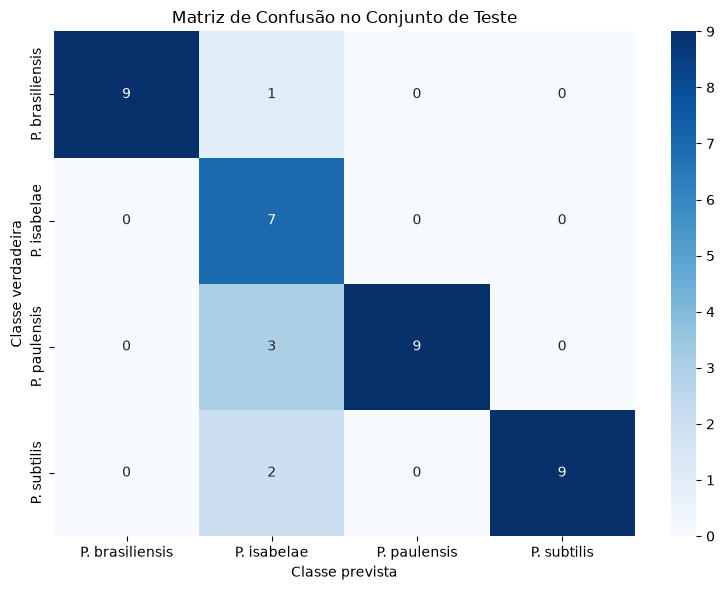

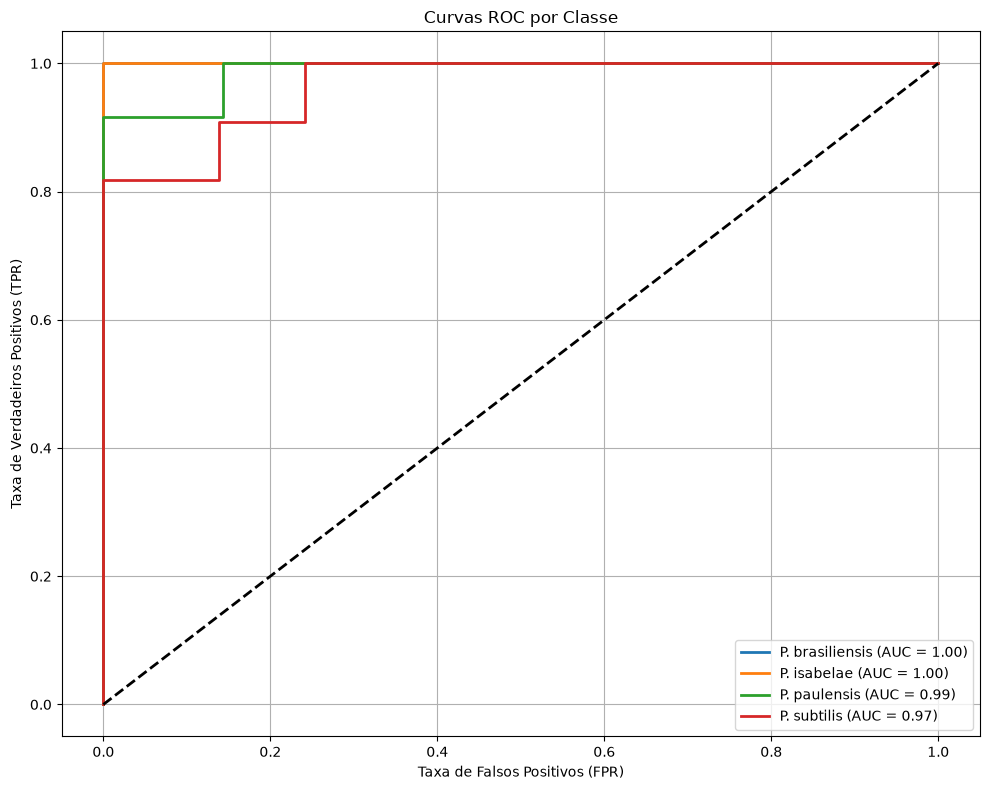

####################################################################################
Fold: 1 | Pooling: AdaptiveAvgPool1d(output_size=1)

Acurácia final: 95.00%
F1-score macro: 0.95
F1-score weighted: 0.95

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.92      1.00      0.96        11
    P. isabelae       1.00      1.00      1.00         7
   P. paulensis       0.92      1.00      0.96        12
    P. subtilis       1.00      0.80      0.89        10

       accuracy                           0.95        40
      macro avg       0.96      0.95      0.95        40
   weighted avg       0.95      0.95      0.95        40



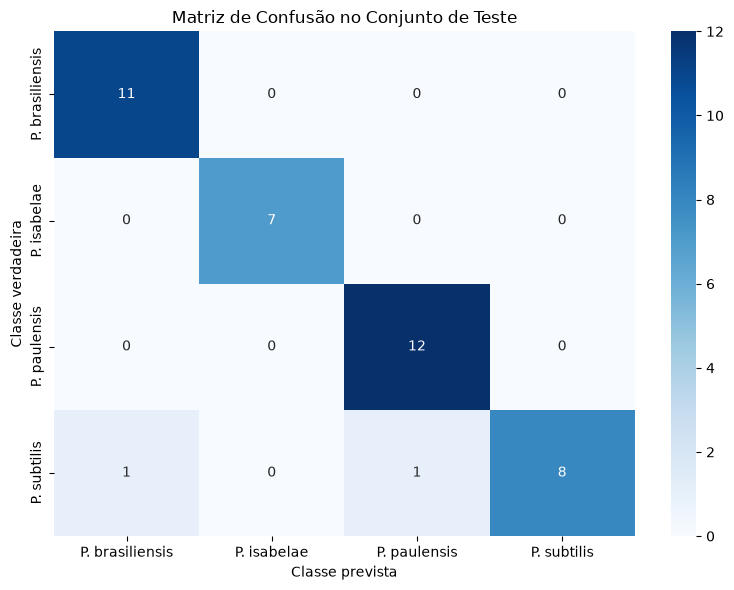

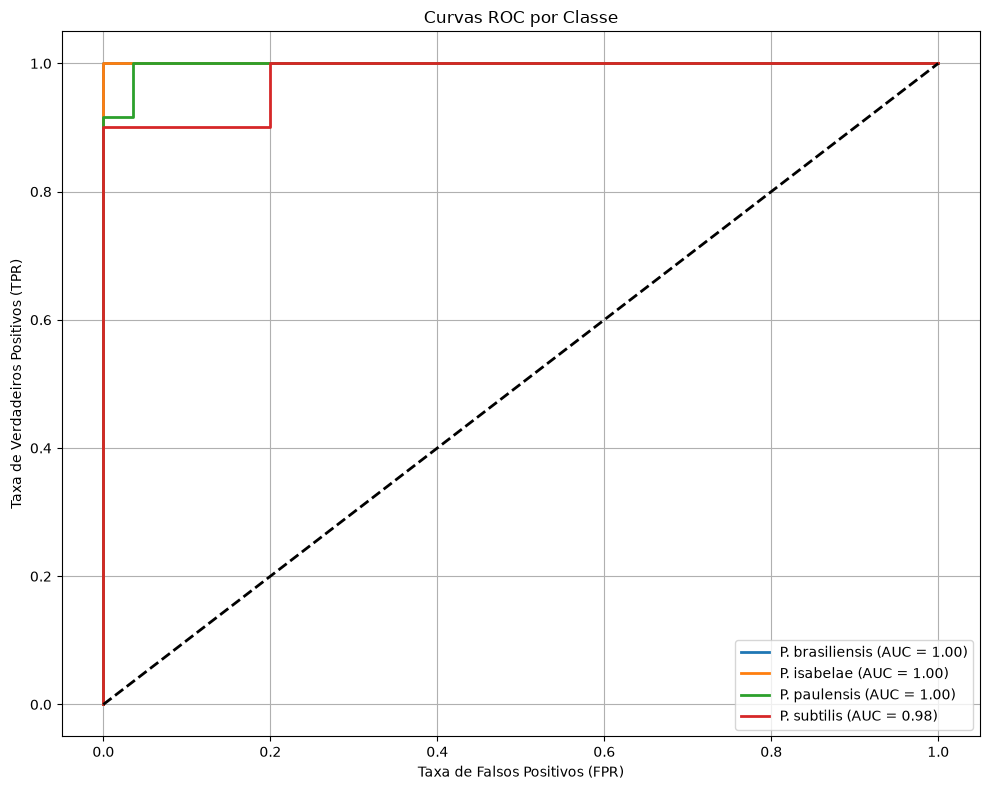

####################################################################################
Fold: 2 | Pooling: AdaptiveAvgPool1d(output_size=1)

Acurácia final: 87.50%
F1-score macro: 0.89
F1-score weighted: 0.87

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       0.69      1.00      0.81        11
    P. isabelae       1.00      1.00      1.00         6
   P. paulensis       1.00      0.58      0.74        12
    P. subtilis       1.00      1.00      1.00        11

       accuracy                           0.88        40
      macro avg       0.92      0.90      0.89        40
   weighted avg       0.91      0.88      0.87        40



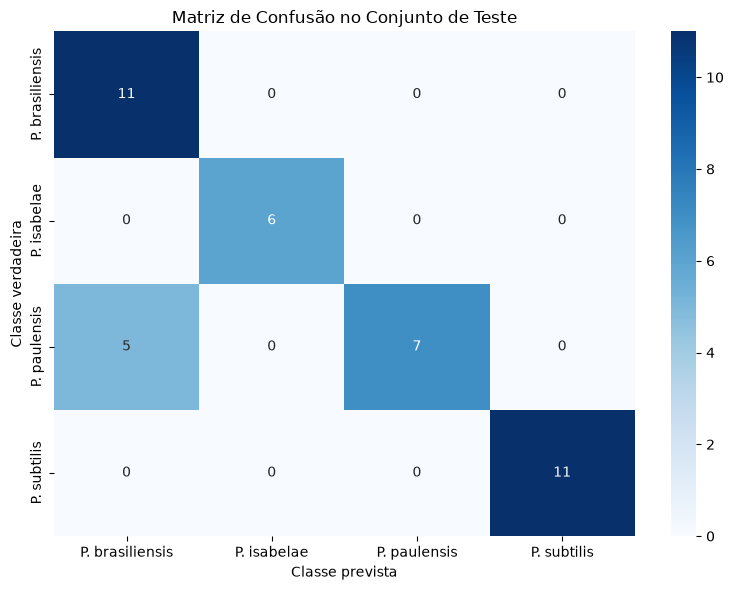

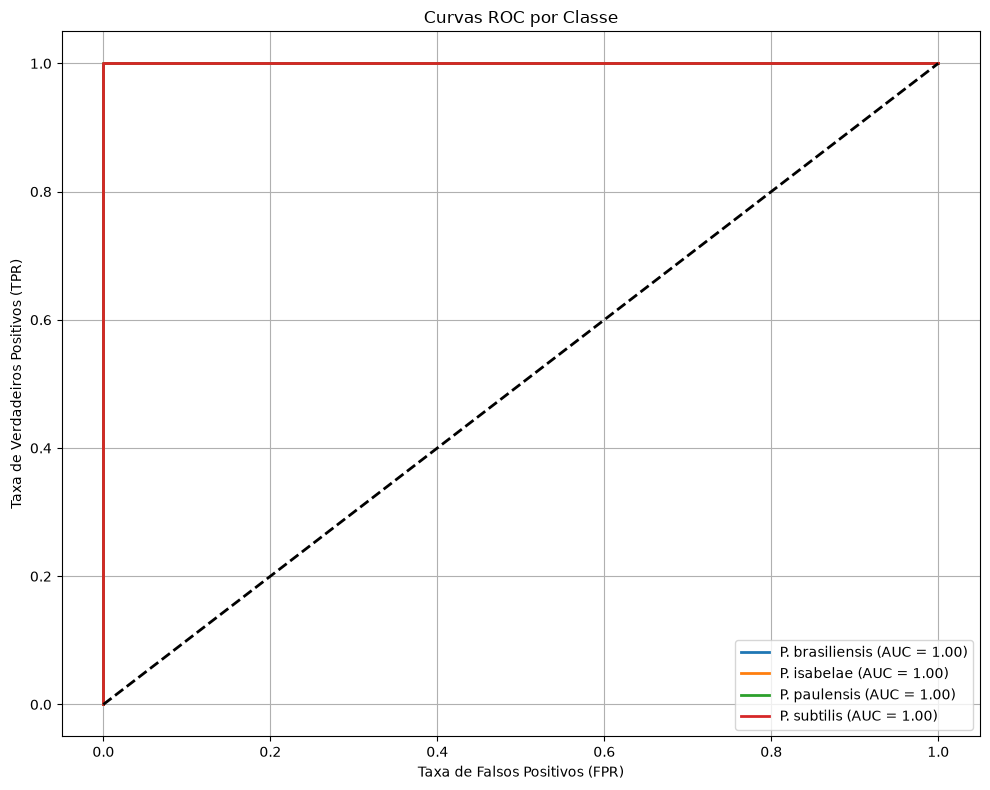

####################################################################################
Fold: 3 | Pooling: AdaptiveAvgPool1d(output_size=1)

Acurácia final: 95.00%
F1-score macro: 0.94
F1-score weighted: 0.95

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00        10
    P. isabelae       1.00      0.71      0.83         7
   P. paulensis       1.00      1.00      1.00        12
    P. subtilis       0.85      1.00      0.92        11

       accuracy                           0.95        40
      macro avg       0.96      0.93      0.94        40
   weighted avg       0.96      0.95      0.95        40



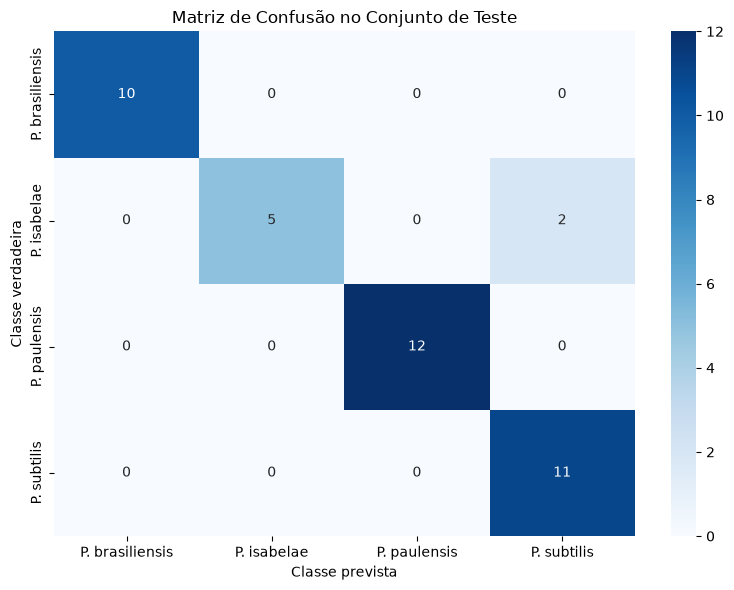

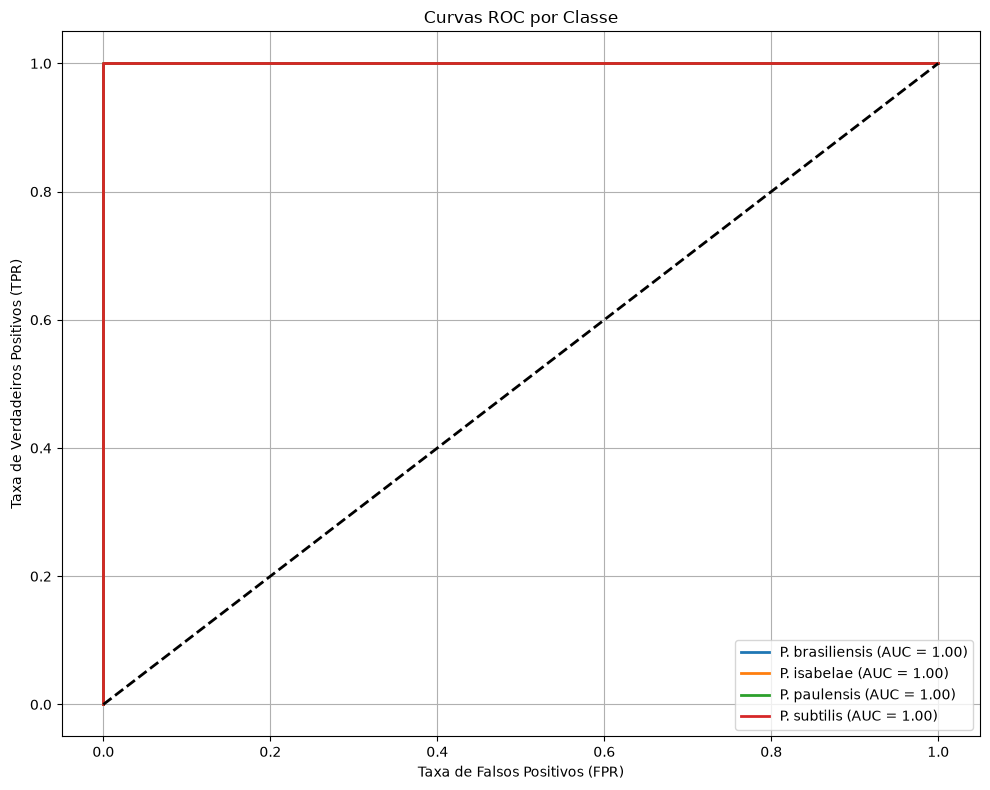

####################################################################################
Fold: 4 | Pooling: AdaptiveAvgPool1d(output_size=1)

Acurácia final: 80.00%
F1-score macro: 0.78
F1-score weighted: 0.80

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      0.90      0.95        10
    P. isabelae       1.00      0.43      0.60         7
   P. paulensis       0.60      1.00      0.75        12
    P. subtilis       1.00      0.73      0.84        11

       accuracy                           0.80        40
      macro avg       0.90      0.76      0.78        40
   weighted avg       0.88      0.80      0.80        40



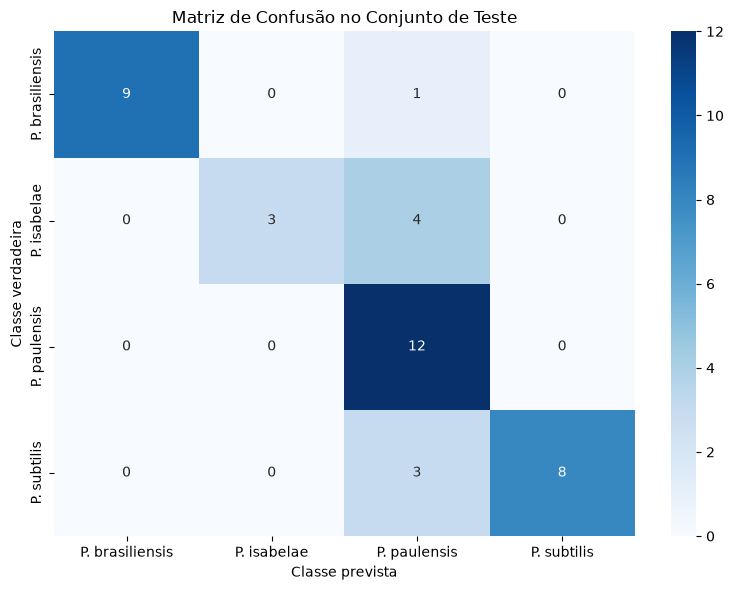

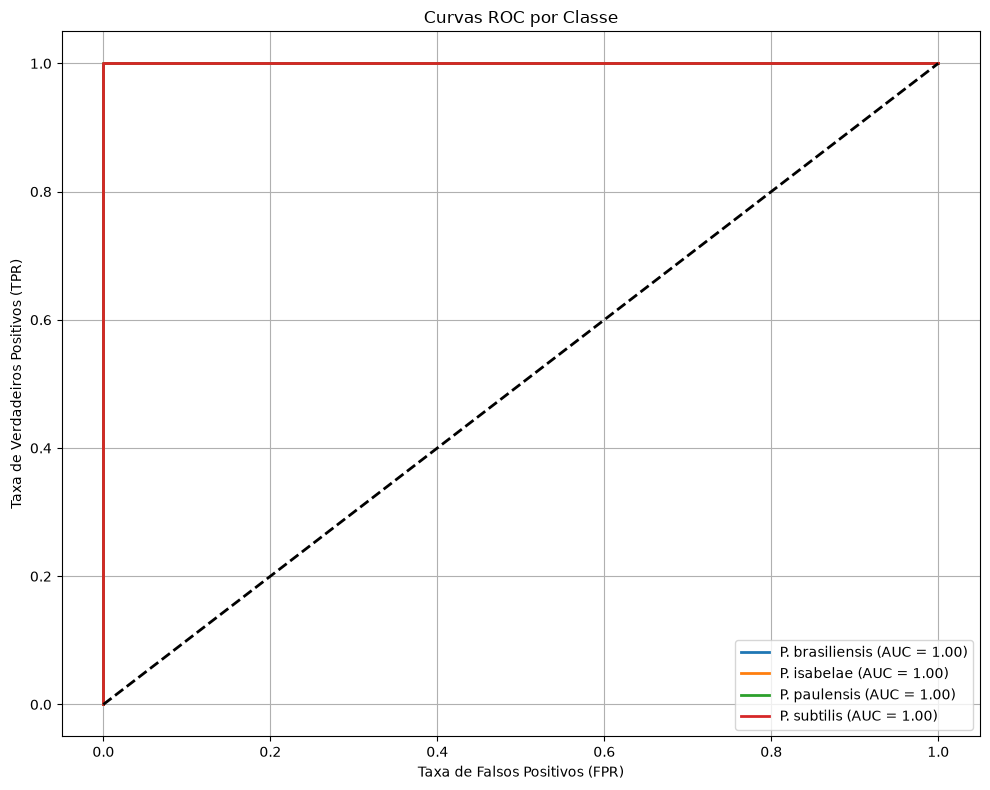

In [ ]:
for pooling in poolings:
    for fold in range(1,5):
        print("####################################################################################")
        print(f"Fold: {fold} | Pooling: {pooling}")
        evaluate_model(classes_shrimp, cros_validation_history[pooling].get_all_label_fold(fold),cros_validation_history[pooling].get_all_pred_fold(fold), cros_validation_history[pooling].get_all_prob_fold(fold) )

In [ ]:
import csv
import os

os.makedirs("../resultados/hiperparametros", exist_ok=True)

with open("../resultados/hiperparametros/learning_rates_metrics_cv.csv","w",newline="",encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "fold",
        "learning_rate",
        "loss",
        "accuracy",
        "f1"
    ])

    for lr in learning_rates:

        metrics = cros_validation_history[lr].get_metrics()

        for fold, metric in enumerate(metrics, start=1):

            writer.writerow([
                fold,
                lr,
                metric["loss"],
                metric["acc"],
                metric["f1"]
            ])

In [ ]:
with open(
    "../resultados/hiperparametros/learning_rates_predictions_cv.csv",
    "w",
    newline="",
    encoding="utf-8"
) as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "fold",
        "learning_rate",
        "sample",
        "true_label",
        "predicted_label",
        "prob_0",
        "prob_1",
        "prob_2",
        "prob_3"
    ])

    for lr in learning_rates:

        history = cros_validation_history[lr]

        for fold in range(1, 6):

            labels = history.get_all_label_fold(fold)
            preds = history.get_all_pred_fold(fold)
            probs = history.get_all_prob_fold(fold)

            for sample, (label, pred, prob) in enumerate(
                zip(labels, preds, probs)
            ):

                writer.writerow([
                    fold,
                    lr,
                    sample,
                    label,
                    pred,
                    prob[0],
                    prob[1],
                    prob[2],
                    prob[3]
                ])

Salvando métricas variando batch_size

In [61]:
with open("../resultados/hiperparametros/batch_sizes_metrics_cv.csv","w",newline="",encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "fold",
        "bath_sizes",
        "loss",
        "accuracy",
        "f1"
    ])

    for batch in batch_sizes:

        metrics = cros_validation_history[batch].get_metrics()

        for fold, metric in enumerate(metrics, start=1):

            writer.writerow([
                fold,
                batch,
                metric["loss"],
                metric["acc"],
                metric["f1"]
            ])

In [63]:
with open(
    "../resultados/hiperparametros/batch_sizes_predictions_cv.csv",
    "w",
    newline="",
    encoding="utf-8"
) as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "fold",
        "batch_size",
        "sample",
        "true_label",
        "predicted_label",
        "prob_0",
        "prob_1",
        "prob_2",
        "prob_3"
    ])

    for batch in batch_sizes:

        history = cros_validation_history[batch]

        for fold in range(1, 6):

            labels = history.get_all_label_fold(fold)
            preds = history.get_all_pred_fold(fold)
            probs = history.get_all_prob_fold(fold)

            for sample, (label, pred, prob) in enumerate(
                zip(labels, preds, probs)
            ):

                writer.writerow([
                    fold,
                    batch,
                    sample,
                    label,
                    pred,
                    prob[0],
                    prob[1],
                    prob[2],
                    prob[3]
                ])

In [60]:
with open("../resultados/hiperparametros/poolings_metrics_cv.csv","w",newline="",encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "fold",
        "poolings",
        "loss",
        "accuracy",
        "f1"
    ])

    for pooling in poolings:

        metrics = cros_validation_history[pooling].get_metrics()

        for fold, metric in enumerate(metrics, start=1):

            name_pooling = "max"

            if isinstance(pooling, nn.AdaptiveAvgPool1d):
                name_pooling = "avg"

            writer.writerow([
                fold,
                name_pooling,
                metric["loss"],
                metric["acc"],
                metric["f1"]
            ])

In [64]:
with open(
    "../resultados/hiperparametros/poolings_predictions_cv.csv",
    "w",
    newline="",
    encoding="utf-8"
) as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "fold",
        "pooling",
        "sample",
        "true_label",
        "predicted_label",
        "prob_0",
        "prob_1",
        "prob_2",
        "prob_3"
    ])

    for pooling in poolings:

        history = cros_validation_history[pooling]

        for fold in range(1, 6):

            labels = history.get_all_label_fold(fold)
            preds = history.get_all_pred_fold(fold)
            probs = history.get_all_prob_fold(fold)

            for sample, (label, pred, prob) in enumerate(
                zip(labels, preds, probs)
            ):
                
                name_pooling = "max"

                if isinstance(pooling, nn.AdaptiveAvgPool1d):
                    name_pooling = "avg"


                writer.writerow([
                    fold,
                    name_pooling,
                    sample,
                    label,
                    pred,
                    prob[0],
                    prob[1],
                    prob[2],
                    prob[3]
                ])